# Import

In [317]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import hashlib
import json
import uuid
from pathlib import Path
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
import yaml
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy
from matplotlib.colors import LogNorm

from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


In [318]:
import reboost
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample
from reboost.utils import get_remage_detector_uids





In [456]:
from remage import remage_run



# functions

In [4]:
def find_matching_background_runs(db, detector, measure, campaign="c1"):
    configuration = db.hardware.configuration[detector][campaign]

    physics_runs = configuration[measure]
    background_runs = configuration["bkg"]

    matches = {}

    for run, data in sorted(physics_runs.items()):
        if not run.startswith("run"):
            continue

        card = data["daq_settings"]["flashcam"]["card_interface"]

        matching_bkg = [
            bkg_run
            for bkg_run, bkg_data in sorted(background_runs.items())
            if bkg_run.startswith("run")
            and bkg_data["daq_settings"]["flashcam"]["card_interface"] == card
        ]

        matches[run] = {
            "card_interface": card,
            "background_runs": matching_bkg,
        }

    return matches

In [5]:

def gaussian_bin_counts(edges, area, mu, sigma):
    z = (edges - mu) / (np.sqrt(2) * sigma)
    return area * 0.5 * np.diff(erf(z))


def left_tail_bin_counts(edges, area, mu, sigma, tau):
    cdf = exponnorm.sf(
        mu - edges,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    return area * np.maximum(np.diff(cdf), 0)


def step_primitive(x, mu, sigma):
    u = (x - mu) / (np.sqrt(2) * sigma)

    return 0.5 * (
        (x - mu) * erfc(u)
        - sigma * np.sqrt(2 / np.pi) * np.exp(-u**2)
    )


def am60_components(edges, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = gaussian_bin_counts(edges, area, mu, sigma)
    tail = left_tail_bin_counts(
        edges, tail_area, mu, sigma, tau
    )

    continuum = (
        background * np.diff(edges)
        + step * np.diff(
            step_primitive(edges, mu, sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def am60_density(x, parameters):
    (
        area, mu, sigma,
        tail_area, tau,
        background, step,
    ) = parameters

    peak = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        mu - x,
        tau / sigma,
        loc=0,
        scale=sigma,
    )

    continuum = (
        background
        + step * 0.5 * erfc(
            (x - mu) / (np.sqrt(2) * sigma)
        )
    )

    return {
        "gaussian": peak,
        "tail": tail,
        "continuum": continuum,
        "total": peak + tail + continuum,
    }


def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        1e-12,
    )

    deviance = 2 * (
        expected - counts
        + xlogy(counts, counts / expected)
    )

    return (
        np.sign(expected - counts)
        * np.sqrt(np.maximum(deviance, 0))
    )



In [6]:


def am100_components(edges, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    edges = np.asarray(edges, dtype=float)
    widths = np.diff(edges)

    def gaussian_counts(N, mu):
        return N * np.diff(ndtr((edges - mu) / sigma))

    def step_counts(S, mu):
        # Densità dello step: S * Phi((mu - E) / sigma)
        # Primitiva rispetto all'energia.
        z = (mu - edges) / sigma
        phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

        primitive = (
            (edges - mu) * ndtr(z)
            - sigma * phi
        )

        return S * np.maximum(np.diff(primitive), 0.0)

    g1 = gaussian_counts(N1, mu1)
    g2 = gaussian_counts(N2, mu2)
    g3 = gaussian_counts(N3, mu3)

    step1 = step_counts(S1, mu1)
    step2 = step_counts(S2, mu3)

    background = B * widths

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


def poisson_residuals_am100(parameters, edges, y):
    expected = am100_components(edges, parameters)["total"]
    expected = np.maximum(expected, np.finfo(float).tiny)

    # Residui della devianza di Poisson, inclusi i bin vuoti.
    deviance = expected - y
    positive = y > 0

    deviance[positive] += y[positive] * (
        np.log(y[positive]) - np.log(expected[positive])
    )

    return np.sign(y - expected) * np.sqrt(
        2.0 * np.maximum(deviance, 0.0)
    )


def fit_am_100(counts, bins, fit_range=(96.0, 106.0)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if not np.isfinite(bins).all() or np.any(np.diff(bins) <= 0):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    # 3 aree, 3 centroidi, 1 sigma, 2 step, 1 fondo.
    n_parameters = 10

    if indices.size <= n_parameters:
        raise ValueError("Troppi pochi bin nella finestra di fit.")

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError("Nessun conteggio nella finestra di fit.")

    if edges[0] >= 99.0 or edges[-1] <= 103.0:
        raise ValueError("La finestra deve includere tutti e tre i picchi.")

    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2
    density = y / widths

    background = max(
        float(np.percentile(density, 10)),
        1e-3,
    )

    sigma_guess = 0.4

    def area_guess(mu):
        height = max(
            float(density[np.argmin(np.abs(centers - mu))])
            - background,
            1.0,
        )
        return height * np.sqrt(2 * np.pi) * sigma_guess

    # Ordine: N1, mu1, N2, mu2, N3, mu3, sigma, S1, S2, B.
    p0 = [
        area_guess(99.0), 99.0,
        area_guess(101.1), 101.1,
        area_guess(103.0), 103.0,
        sigma_guess,
        background * 0.5,
        background * 0.5,
        background,
    ]

    lower = [
        0.0, 98.5,
        0.0, 100.6,
        0.0, 102.5,
        0.05,
        0.0, 0.0,
        0.0,
    ]

    upper = [
        np.inf, 99.5,
        np.inf, 101.6,
        np.inf, 103.5,
        1.2,
        np.inf, np.inf,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals_am100,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    rank = np.linalg.matrix_rank(fit.jac)
    full_rank = rank == n_parameters

    covariance = (
        np.linalg.pinv(fit.jac.T @ fit.jac)
        if full_rank
        else np.full((n_parameters, n_parameters), np.nan)
    )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    peak_indices = [0, 2, 4]
    areas = fit.x[peak_indices].copy()

    if not np.isfinite(areas).all() or np.any(areas <= 0):
        raise ValueError("Aree dei picchi non valide.")

    return {
        "parameter_names": [
            "N1", "mu1",
            "N2", "mu2",
            "N3", "mu3",
            "sigma",
            "S1", "S2",
            "B",
        ],
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,
        "area_peak": areas,
        "area_peak_errors": errors[peak_indices],
        "mu": fit.x[[1, 3, 5]],
        "mu_errors": errors[[1, 3, 5]],
        "fwhm": 2.35482 * fit.x[6],
        "fwhm_error": 2.35482 * errors[6],
        "edges": edges,
        "counts": y,
        "components": am100_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,
        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr


def am100_density(x, parameters):
    (
        N1, mu1,
        N2, mu2,
        N3, mu3,
        sigma,
        S1, S2,
        B,
    ) = parameters

    x = np.asarray(x, dtype=float)

    def gaussian(N, mu):
        return (
            N / (np.sqrt(2 * np.pi) * sigma)
            * np.exp(-0.5 * ((x - mu) / sigma)**2)
        )

    g1 = gaussian(N1, mu1)
    g2 = gaussian(N2, mu2)
    g3 = gaussian(N3, mu3)

    step1 = S1 * ndtr((mu1 - x) / sigma)
    step2 = S2 * ndtr((mu3 - x) / sigma)
    background = np.full_like(x, B)

    return {
        "gaussian_99": g1,
        "gaussian_101": g2,
        "gaussian_103": g3,
        "step_99": step1,
        "step_103": step2,
        "background": background,
        "total": g1 + g2 + g3 + step1 + step2 + background,
    }


# ============================================================
# FIT FIGURE: EXACTLY (5, 3)
# ============================================================

def plot_am100_fit(result, detector, run, meta, dpi=300):
    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    edges = result["edges"]
    centers = (edges[:-1] + edges[1:]) / 2
    widths = np.diff(edges)
    width = widths[0]

    if not np.allclose(widths, width):
        plt.close(fig)
        raise ValueError("Questo plot richiede bin di larghezza uniforme.")

    x = np.linspace(edges[0], edges[-1], 3000)
    smooth = am100_density(x, result["parameters"])

    ax.stairs(
        result["counts"],
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total", "darkorange", "-"),
        ("gaussian_99", "Gaussian 99 keV", "crimson", "--"),
        ("gaussian_101", "Gaussian 101.1 keV", "deepskyblue", "--"),
        ("gaussian_103", "Gaussian 103 keV", "green", "--"),
        ("step_99", "Step 99 keV", "purple", "--"),
        ("step_103", "Step 103 keV", "brown", "--"),
        ("background", "Background", "gray", "--"),
    ]:
        curve = smooth[key] * width

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = result["counts"][result["counts"] > 0]
    ymax = max(
        result["counts"].max(),
        smooth["total"].max() * width,
    )

    #ax.set_ylim(
    #    max(0.1, min(100.0, positive.min() * 0.5)),
   #     ymax * 2,
   # )

    ax.set_ylim(
        0.01, 2e3
    )

    p = result["parameters"]
    errors = result["errors"]

    text = (
        rf"$A_1={p[0]:.0f}\pm{errors[0]:.0f}$ counts" "\n"
        rf"$\mu_1={p[1]:.4f}\pm{errors[1]:.4f}$ keV" "\n"
        rf"$A_2={p[2]:.0f}\pm{errors[2]:.0f}$ counts" "\n"
        rf"$\mu_2={p[3]:.4f}\pm{errors[3]:.4f}$ keV" "\n"
        rf"$A_3={p[4]:.0f}\pm{errors[4]:.0f}$ counts" "\n"
        rf"$\mu_3={p[5]:.4f}\pm{errors[5]:.4f}$ keV" "\n"
        rf"$\sigma={p[6]:.4f}\pm{errors[6]:.4f}$ keV" "\n"
        rf"$S_1={p[7]:.1f}\pm{errors[7]:.1f}$ counts/keV" "\n"
        rf"$S_2={p[8]:.1f}\pm{errors[8]:.1f}$ counts/keV" "\n"
        rf"$B={p[9]:.1f}\pm{errors[9]:.1f}$ counts/keV" "\n"
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.4f} keV\n"
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}"
    )

    ax.text(
        0.98, 0.97,
        text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 2,
        },
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(f"Counts / {width:g} keV", fontsize=7)
    ax.legend(fontsize=5.5, loc="upper left")

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel("Deviance\nresidual", fontsize=6)
    ax_res.set_xlabel("Energy (keV)", fontsize=7)
    ax_res.set_xlim(edges[0], edges[-1])

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



In [61]:

def am60_components(edges, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    edges = np.asarray(edges, dtype=float)

    gaussian = area * np.maximum(
        np.diff(ndtr((edges - mu) / sigma)),
        0.0,
    )

    distribution = exponnorm(
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    cdf = distribution.cdf(edges)
    sf = distribution.sf(edges)

    probability = np.where(
        cdf[:-1] > 0.5,
        sf[:-1] - sf[1:],
        cdf[1:] - cdf[:-1],
    )

    tail = tail_area * np.maximum(probability, 0.0)

    z = (mu - edges) / sigma
    phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

    primitive = (
        (edges - mu) * ndtr(z)
        - sigma * phi
    )

    step = S * np.maximum(
        np.diff(primitive), 0.0
    )

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }
    
def am60_density(x, parameters):
    area, mu, sigma, tail_area, tau, S = parameters

    x = np.asarray(x, dtype=float)

    gaussian = (
        area / (np.sqrt(2 * np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

    tail = tail_area * exponnorm.pdf(
        x,
        tau / sigma,
        loc=mu,
        scale=sigma,
    )

    step = S * ndtr((mu - x) / sigma)

    return {
        "gaussian": gaussian,
        "tail": tail,
        "step": step,
        "total": gaussian + tail + step,
    }


# ============================================================
# POISSON DEVIANCE RESIDUALS
# ============================================================

def poisson_residuals(parameters, edges, counts):
    expected = np.maximum(
        am60_components(edges, parameters)["total"],
        np.finfo(float).tiny,
    )

    half_deviance = expected.copy()
    positive = counts > 0

    observed = counts[positive]
    predicted = expected[positive]

    delta = (predicted - observed) / observed

    near = np.abs(delta) < 0.01
    terms = np.empty_like(delta)

    # Stable expansion near predicted == observed.
    d = delta[near]

    terms[near] = d**2 * (
        0.5 - d / 3 + d**2 / 4
        - d**3 / 5 + d**4 / 6
    )

    terms[~near] = (
        delta[~near]
        + np.log(observed[~near])
        - np.log(predicted[~near])
    )

    half_deviance[positive] = observed * terms

    # Positive residual: data exceed the model.
    return np.sign(counts - expected) * np.sqrt(
        2.0 * np.maximum(half_deviance, 0.0)
    )


# ============================================================
# FIT CALIBRATED RAW COUNTS
# ============================================================

def fit_am60(counts, bins, fit_range=(56, 62)):
    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if counts.ndim != 1 or bins.ndim != 1:
        raise ValueError("counts e bins devono essere 1D.")

    if counts.size == 0 or bins.size != counts.size + 1:
        raise ValueError("Dimensioni istogramma incompatibili.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Conteggi non validi.")

    if (
        not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi non validi.")

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    indices = np.flatnonzero(
        (bins[:-1] >= xmin)
        & (bins[1:] <= xmax)
    )

    n_parameters = len(PARAMETER_NAMES)

    if indices.size <= n_parameters:
        raise ValueError(
            "Troppi pochi bin per un fit con 6 parametri."
        )

    first = indices[0]
    last = indices[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]

    if y.sum() <= 0:
        raise ValueError(
            "Nessun conteggio nella finestra di fit."
        )

    if not (edges[0] < 59.54 < edges[-1]):
        raise ValueError(
            "La finestra deve includere il picco a 59.54 keV."
        )

    centers = (edges[:-1] + edges[1:]) / 2
    density = y / np.diff(edges)

    mu_guess = 59.54
    sigma_guess = 0.3

    # Estimate the step plateau below the peak.
    low_energy = centers < 58.5

    step_guess = max(
        float(np.percentile(density[low_energy], 20))
        if np.any(low_energy)
        else float(np.percentile(density, 20)),
        1e-3,
    )

    index = np.argmin(np.abs(centers - mu_guess))

    height = max(
        float(density[index]) - 0.5 * step_guess,
        1.0,
    )

    area_guess = (
        height * np.sqrt(2 * np.pi) * sigma_guess
    )

    # area_peak, mu, sigma, area_tail, tau, step
    p0 = [
        area_guess,
        mu_guess,
        sigma_guess,
        area_guess * 0.02,
        1.0,
        step_guess,
    ]

    lower = [
        0.0,
        58.8,
        0.05,
        0.0,
        0.05,
        0.0,
    ]

    upper = [
        np.inf,
        60.3,
        1.2,
        np.inf,
        10.0,
        np.inf,
    ]

    fit = least_squares(
        poisson_residuals,
        p0,
        bounds=(lower, upper),
        args=(edges, y),
        x_scale="jac",
        max_nfev=20000,
    )

    if not fit.success:
        raise RuntimeError(f"Fit fallito: {fit.message}")

    # Column scaling reduces sensitivity of the rank check
    # to the very different parameter units and magnitudes.
    column_norms = np.linalg.norm(fit.jac, axis=0)
    safe_norms = np.where(column_norms > 0, column_norms, 1.0)
    scaled_jacobian = fit.jac / safe_norms

    full_rank = (
        np.linalg.matrix_rank(scaled_jacobian)
        == n_parameters
    )

    if full_rank:
        _, singular_values, vt = np.linalg.svd(
            scaled_jacobian,
            full_matrices=False,
        )

        scaled_covariance = (
            vt.T / singular_values**2
        ) @ vt

        covariance = (
            scaled_covariance
            / safe_norms[:, None]
            / safe_norms[None, :]
        )

    else:
        covariance = np.full(
            (n_parameters, n_parameters),
            np.nan,
        )

    errors = np.sqrt(
        np.maximum(np.diag(covariance), 0.0)
    )

    if not np.isfinite(fit.x).all() or fit.x[0] <= 0:
        raise ValueError(
            "Parametri o area gaussiana non validi."
        )

    result = {
        "parameter_names": PARAMETER_NAMES.copy(),
        "parameters": fit.x,
        "errors": errors,
        "covariance": covariance,

        "area_peak": fit.x[0],
        "area_peak_error": errors[0],

        "mu": fit.x[1],
        "mu_error": errors[1],

        "sigma": fit.x[2],
        "sigma_error": errors[2],

        "area_tail": fit.x[3],
        "area_tail_error": errors[3],

        "tau": fit.x[4],
        "tau_error": errors[4],

        "step": fit.x[5],
        "step_error": errors[5],

        # FWHM of the Gaussian component only.
        "fwhm": 2.35482 * fit.x[2],
        "fwhm_error": 2.35482 * errors[2],

        "edges": edges,
        "counts": y,
        "components": am60_components(edges, fit.x),
        "residuals": fit.fun,
        "deviance": float(np.sum(fit.fun**2)),
        "ndof": y.size - n_parameters,

        "full_rank": full_rank,
        "at_bounds": bool(np.any(fit.active_mask != 0)),
        "active_mask": fit.active_mask,
        "nfev": fit.nfev,
        "message": fit.message,
    }

    for name, value, error in zip(
        PARAMETER_NAMES,
        fit.x,
        errors,
    ):
        print(f"{name} = {value:.6g} ± {error:.3g}")

    print(
        f"FWHM gaussiana = {result['fwhm']:.5f}"
        f" ± {result['fwhm_error']:.3g} keV\n"
        f"Deviance / ndof = "
        f"{result['deviance']:.2f}/{result['ndof']}"
    )

    if result["at_bounds"]:
        names_at_bounds = [
            name
            for name, active in zip(
                PARAMETER_NAMES,
                fit.active_mask,
            )
            if active != 0
        ]

        print(
            "CHECK FIT: parametri al limite: "
            + ", ".join(names_at_bounds)
        )

    if not full_rank:
        print("CHECK FIT: incertezze non identificabili.")

    return result


# ============================================================
# FIT FIGURE: (5, 3)
# ============================================================

def plot_am60_fit(result, detector, run, meta, dpi=300):
    edges = result["edges"]
    widths = np.diff(edges)
    centers = (edges[:-1] + edges[1:]) / 2

    uniform = np.allclose(widths, widths[0])

    if uniform:
        values = result["counts"]
        curve_scale = widths[0]
        ylabel = f"Counts / {widths[0]:g} keV"
    else:
        values = result["counts"] / widths
        curve_scale = 1.0
        ylabel = "Counts / keV"

    x = np.linspace(
        edges[0], edges[-1], 3000
    )

    smooth = am60_density(
        x, result["parameters"]
    )

    fig, (ax, ax_res) = plt.subplots(
        2, 1,
        figsize=(5, 3),
        sharex=True,
        height_ratios=[3, 1],
        layout="constrained",
        dpi=dpi,
    )

    ax.stairs(
        values,
        edges,
        color="navy",
        linewidth=0.8,
        label="Data",
    )

    for key, label, color, linestyle in [
        ("total", "Total fit", "darkorange", "-"),
        ("gaussian", "Gaussian", "crimson", "--"),
        ("tail", "Right tail", "deepskyblue", "--"),
        ("step", "Step", "purple", "--"),
    ]:
        curve = smooth[key] * curve_scale

        ax.plot(
            x,
            np.where(curve > 0, curve, np.nan),
            color=color,
            linestyle=linestyle,
            linewidth=0.9,
            label=label,
        )

    ax.set_yscale("log")

    positive = values[values > 0]

    ax.set_ylim(
        min(0.5, positive.min() / 2),
        max(
            values.max(),
            smooth["total"].max() * curve_scale,
        ) * 2,
    )

    labels = [
        "A_G", "mu", "sigma",
        "A_right", "tau_right", "S",
    ]

    units = [
        "counts", "keV", "keV",
        "counts", "keV", "counts/keV",
    ]

    lines = [
        f"{label}={value:.4g} ± {error:.2g} {unit}"
        for label, value, error, unit in zip(
            labels,
            result["parameters"],
            result["errors"],
            units,
        )
    ]

    lines += [
        f"FWHM={result['fwhm']:.4f}"
        f" ± {result['fwhm_error']:.3g} keV",
        f"D/ndof={result['deviance']:.1f}/{result['ndof']}",
    ]

    ax.text(
        0.98, 0.97,
        "\n".join(lines),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=5,
        color="navy",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=2,
        ),
    )

    pos = meta["source_position"]

    ax.set_title(
        f"{detector}/{run} | "
        f"r={float(pos['r_in_mm']):g}, "
        f"z={float(pos['z_in_mm']):g} mm, "
        f"φ={float(pos['phi_in_deg']):g}° | "
        f"t={float(meta['run_live_time_in_s']) / 3600:g} h",
        fontsize=7,
    )

    ax.set_ylabel(ylabel, fontsize=7)
    ax.legend(
        fontsize=5.5,
        loc="upper left",
        frameon=False,
    )

    ax_res.axhline(
        0,
        color="gray",
        linestyle="--",
        linewidth=0.6,
    )

    ax_res.plot(
        centers,
        result["residuals"],
        ".",
        color="navy",
        markersize=2,
    )

    ax_res.set_ylabel(
        "Deviance\nresidual",
        fontsize=6,
    )

    ax_res.set_xlabel(
        "Energy (keV)",
        fontsize=7,
    )

    ax_res.set_xlim(
        edges[0], edges[-1]
    )

    for axis in (ax, ax_res):
        axis.tick_params(labelsize=6)

    return fig



# Metadata HADES

In [62]:
detector = "V03421A"
run = 3
version = "v1.2.1"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS1_top_dlt"
#detector = "666"
#run = 1
campaign = "c1"



In [63]:
run_key = f"run{int(run):04d}"   # run0002: metadati
run_tag = f"r{int(run):03d}"     # r002: file LH5

In [64]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)


In [65]:
db_data = db.hardware.configuration[detector]["c1"][measure][run_key]

In [66]:
#db_bkg = db.hardware.configuration[detector]["c1"]["bkg"][f'run0001']

# data and background

In [13]:
import glob
#measure = 'th_HS2_top_psa'

def find_same_card_runs(
    db,
    detector,
    version=version,
    measure=measure,
    campaign=campaign,
):
    base = (
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}"
    )

    print(base)

    def get_available_runs(measurement):
        try:
            config = (
                db.hardware.configuration[detector]
                [campaign][measurement]
            )
        except (KeyError, FileNotFoundError):
            print(
                f"{detector}: metadata missing for "
                f"{campaign}/{measurement}."
            )
            return {}

        available = {}

        print(f"\n--- {detector} / {measurement}: all cards ---")

        for run in sorted(config.keys()):
            if not (
                run.startswith("run")
                and run[3:].isdigit()
            ):
                continue

            try:
                meta = config[run]

                card = (
                    meta["daq_settings"]["flashcam"]
                    ["card_interface"]
                )

                if card is None or card == "":
                    raise ValueError("Empty card_interface.")

                # Print even if physics files are unavailable.
                print(
                    f"{detector}/{measurement}/{run} | "
                    f"card_interface: {card}"
                )

                # run0001 -> r001
                run_tag = f"r{int(run[3:]):03d}"

                pattern = (
                    f"{base}/{measurement}/"
                    f"char_data-{detector}-{measurement}-"
                    f"{run_tag}-*-tier_hit.lh5"
                )

                files = sorted(glob.glob(pattern))

                if not files:
                    print(
                        f"  No physics files found: "
                        f"{measurement}/{run} excluded from pairing."
                    )
                    continue

                available[run] = {
                    "card_interface": card,
                    "metadata": meta,
                    "files": files,
                }

            except (
                KeyError,
                FileNotFoundError,
                TypeError,
                ValueError,
            ) as exc:
                print(
                    f"Skipping {detector}/{measurement}/{run}: {exc}"
                )

        return available

    measurement_runs = get_available_runs(measure)
    background_runs = get_available_runs("bkg")

    pairs = []

    print(f"\n--- {detector}: matching pairs ---")

    for run_measure, info_measure in measurement_runs.items():
        for run_background, info_background in background_runs.items():
            if (
                info_measure["card_interface"]
                != info_background["card_interface"]
            ):
                continue

            pairs.append({
                "detector": detector,
                "measurement_run": run_measure,
                "background_run": run_background,
                "card_interface": info_measure["card_interface"],
                "measurement_files": info_measure["files"],
                "background_files": info_background["files"],
                "measurement_metadata": info_measure["metadata"],
                "background_metadata": info_background["metadata"],
            })

            print(
                f"{measure}/{run_measure} ↔ bkg/{run_background}\n"
                f"  Card: {info_measure['card_interface']}\n"
                f"  Measurement files: {len(info_measure['files'])}\n"
                f"  Background files: {len(info_background['files'])}"
            )

    if not pairs:
        print(
            "No pairs with matching card_interface "
            "and available physics files."
        )

    return pairs

In [14]:
pairs = find_same_card_runs(
    db,
    detector=detector,
    version=version,
    measure=measure,
    campaign=campaign,
)

# File della prima coppia compatibile.
if pairs:
    file_names = pairs[0]["measurement_files"]
    file_names_bkg = pairs[0]["background_files"]

/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/tier/hit/V03421A/c1

--- V03421A / am_HS1_top_dlt: all cards ---
V03421A/am_HS1_top_dlt/run0001 | card_interface: efb3
V03421A/am_HS1_top_dlt/run0002 | card_interface: efb3
V03421A/am_HS1_top_dlt/run0003 | card_interface: efb3

--- V03421A / bkg: all cards ---
V03421A/bkg/run0001 | card_interface: efb1
V03421A/bkg/run0002 | card_interface: efb1
V03421A/bkg/run0003 | card_interface: efb3

--- V03421A: matching pairs ---
am_HS1_top_dlt/run0001 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42
am_HS1_top_dlt/run0002 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42
am_HS1_top_dlt/run0003 ↔ bkg/run0003
  Card: efb3
  Measurement files: 30
  Background files: 42


In [15]:
from collections.abc import Mapping
from pprint import pformat


def flatten_metadata(obj, prefix=""):
    result = {}

    if isinstance(obj, Mapping):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            result.update(flatten_metadata(value, path))
    else:
        result[prefix] = obj

    return result


config = db.hardware.configuration[detector][campaign]["bkg"]

metadata = {
    run: flatten_metadata(config[run])
    for run in ["run0001", "run0002"]#, "run0003"]
}

fields = sorted({
    field
    for values in metadata.values()
    for field in values
})

for field in fields:
    values = {
        run: pformat(meta.get(field, "<missing>"))
        for run, meta in metadata.items()
    }

    if len(set(values.values())) > 1:
        print(f"\n{field}")

        for run, value in values.items():
            print(f"  {run}: {value}")


elog
  run0001: 'https://elog.legend-exp.org/HADES/369'
  run0002: 'https://elog.legend-exp.org/HADES/382'

high_voltage_in_V
  run0001: 3500
  run0002: 2600

run
  run0001: 'run0001'
  run0002: 'run0002'

run_start_time
  run0001: '240313T142230'
  run0002: '240319T152205'

shifter
  run0001: 'Slava'
  run0002: 'Mariia'


# Data and plot

In [16]:
bkg_tak = '1'
bkg_tak = '3'
background_run_tag = f'r00{bkg_tak}'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [17]:
run_tag

'r003'

In [18]:
file_pattern = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/"
    f"char_data-{detector}-{measure}-{run_tag}-*.lh5"
)


file_background = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)




In [19]:
file_names = sorted(glob.glob(file_pattern))
file_names_bkg = sorted(glob.glob(file_background))


In [20]:
if not file_names:
    raise FileNotFoundError(
        f"Nessun file trovato per {detector}, {measure}, {run_key}:\n"
        f"{file_pattern}"
    )

print(f"{run_key}: {len(file_names)} file trovati")




if not file_names_bkg:
    raise FileNotFoundError(file_background)
print(f"File background trovati: {len(file_names_bkg)}")

run0003: 30 file trovati
File background trovati: 42


In [21]:
background_run_tag

'r003'

In [210]:
import glob
import re
from pathlib import Path

import lh5
import numpy as np


# ============================================================
# CONFIGURATION
# ============================================================

emin = -70
emax = 3000
nbins = int(emax-emin)*10

bins = np.linspace(emin, emax, nbins + 1)

force_rebuild = False

match = re.fullmatch(
    r"(?:run|r)(\d+)",
    str(background_run_tag),
)

if match is None:
    raise ValueError(
        f"background_run_tag non valido: {background_run_tag}"
    )

background_run_number = int(match.group(1))
background_run_tag = f"r{background_run_number:03d}"
background_run_key = f"run{background_run_number:04d}"

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

spectrum_path = spectrum_dir / (
    f"{detector}_{measure}_{run_key}_spectrum.npz"
)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

file_background = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    f"prodenv/ref/{version}/generated/tier/hit/"
    f"{detector}/{campaign}/bkg/"
    f"char_data-{detector}-bkg-{background_run_tag}-*-tier_hit.lh5"
)

file_names_bkg = sorted(glob.glob(file_background))


# ============================================================
# LOAD OR BUILD HISTOGRAMS
# ============================================================

def load_or_build_spectrum(
    path,
    files,
    bins,
    force_rebuild=False,
    apply_qc=True,
):
    path = Path(path)
    bins = np.asarray(bins, dtype=float)

    if apply_qc:
        qc_selection = (
            "~is_discharge & "
            "((is_positive_polarity_candidate == 127) | "
            "(is_positive_polarity_candidate == 63)); "
            "is_low_cuspEmax ignored; no additional energy selection"
        )
    else:
        qc_selection = "No QC applied"

    if (
        bins.ndim != 1
        or bins.size < 2
        or not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi dell'istogramma non validi.")

    # ========================================================
    # CACHE
    # ========================================================

    if path.exists() and not force_rebuild:
        print(f"Carico: {path}", flush=True)

        with np.load(path, allow_pickle=False) as spectrum:
            required = {
                "counts",
                "counts_clean",
                "bins",
                "qc_selection",
            }

            if required.issubset(spectrum.files):
                counts = np.asarray(spectrum["counts"]).copy()
                counts_clean = np.asarray(
                    spectrum["counts_clean"]
                ).copy()
                saved_bins = np.asarray(spectrum["bins"]).copy()

                saved_selection = str(
                    spectrum["qc_selection"].item()
                )

                valid = (
                    saved_selection == qc_selection
                    and saved_bins.shape == bins.shape
                    and np.allclose(
                        saved_bins, bins, rtol=0, atol=1e-8
                    )
                    and counts.shape == (bins.size - 1,)
                    and counts_clean.shape == counts.shape
                    and np.isfinite(counts).all()
                    and np.isfinite(counts_clean).all()
                    and np.all(counts >= 0)
                    and np.all(counts_clean >= 0)
                    and np.all(counts_clean <= counts)
                    and (
                        apply_qc
                        or np.array_equal(counts_clean, counts)
                    )
                )

                if valid:
                    print(f"Selezione: {qc_selection}")
                    print(
                        f"Conteggi originali nei bin: {counts.sum():,}\n"
                        f"Conteggi restituiti nei bin: "
                        f"{counts_clean.sum():,}",
                        flush=True,
                    )
                    return counts, counts_clean

            print(
                "Cache incompatibile con binning o selezione: rigenero.",
                flush=True,
            )

    if len(files) == 0:
        raise FileNotFoundError(
            f"Nessun file LH5 disponibile per creare {path}"
        )

    counts = np.zeros(bins.size - 1, dtype=np.int64)
    counts_clean = np.zeros_like(counts)

    total_events = 0
    selected_events = 0

    # ========================================================
    # READ ALL FILES AND SUM
    # ========================================================

    for index, filename in enumerate(files, start=1):
        print(
            f"File {index}/{len(files)}: {Path(filename).name}",
            flush=True,
        )

        hit = lh5.read("hit", str(filename))

        energy = np.asarray(
            hit["cuspEmax_ctc_cal"].nda
        )

        if energy.ndim != 1:
            raise ValueError(
                f"Energia non monodimensionale in {filename}."
            )

        raw_histogram = np.histogram(
            energy,
            bins=bins,
        )[0]

        counts += raw_histogram
        total_events += energy.size

        if apply_qc:
            discharge_raw = np.asarray(
                hit["is_discharge"].nda
            )

            positive_bits = np.asarray(
                hit["is_positive_polarity_candidate"].nda
            )

            if (
                discharge_raw.shape != energy.shape
                or positive_bits.shape != energy.shape
            ):
                raise ValueError(
                    f"Energia e flag incompatibili in {filename}."
                )

            if not np.isin(discharge_raw, [0, 1]).all():
                raise ValueError(
                    f"is_discharge non booleano in {filename}."
                )

            is_discharge = discharge_raw.astype(bool)

            mask = (
                ~is_discharge
                & (
                    (positive_bits == 127)
                    | (positive_bits == 63)
                )
            )

            counts_clean += np.histogram(
                energy[mask],
                bins=bins,
            )[0]

            selected_events += int(mask.sum())

            del discharge_raw, positive_bits, is_discharge, mask

        else:
            # Background: nessun QC e nessuna lettura dei flag.
            counts_clean += raw_histogram
            selected_events += energy.size

        del hit, energy, raw_histogram

    # ========================================================
    # SAVE
    # ========================================================

    path.parent.mkdir(parents=True, exist_ok=True)

    np.savez_compressed(
        path,
        counts=counts,
        counts_clean=counts_clean,
        bins=bins,
        qc_selection=qc_selection,
        qc_applied=apply_qc,
        total_events=total_events,
        selected_events=selected_events,
    )

    print(
        f"\nSalvato: {path}\n"
        f"Selezione: {qc_selection}\n"
        f"Eventi totali: {total_events:,}\n"
        f"Eventi selezionati, a tutte le energie: "
        f"{selected_events:,}\n"
        f"Conteggi originali nei bin: {counts.sum():,}\n"
        f"Conteggi restituiti nei bin: {counts_clean.sum():,}",
        flush=True,
    )

    return counts, counts_clean




In [211]:
# ============================================================
# SOURCE — APPLY QC
# ============================================================

print("\n=== SOURCE: WITH QC ===")

counts_data, counts_clean = load_or_build_spectrum(
    spectrum_path,
    file_names,
    bins,
    force_rebuild=True,
    apply_qc=True,
)


# ============================================================
# BACKGROUND — NO QC
# ============================================================

print("\n=== BACKGROUND: NO QC ===")

counts_bkg_noQC, counts_bkg = load_or_build_spectrum(
    background_path,
    file_names_bkg,
    bins,
    force_rebuild=False,
    apply_qc=False,
)


=== SOURCE: WITH QC ===
File 1/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T151035Z-tier_hit.lh5
File 2/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T152039Z-tier_hit.lh5
File 3/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T153041Z-tier_hit.lh5
File 4/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T154044Z-tier_hit.lh5
File 5/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T155048Z-tier_hit.lh5
File 6/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T160050Z-tier_hit.lh5
File 7/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T161052Z-tier_hit.lh5
File 8/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T162052Z-tier_hit.lh5
File 9/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T163054Z-tier_hit.lh5
File 10/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T164057Z-tier_hit.lh5
File 11/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T165103Z-tier_hit.lh5
File 12/30: char_data-V03421A-am_HS1_top_dlt-r003-20240324T170105Z-tier_hit.lh5
File 13/30: char_data-V0

In [212]:
hit = lh5.read("hit", str(file_names[0]))

positive = np.asarray(
    hit["is_highly_positive_polarity_candidate"].nda
)

values, numbers = np.unique(
    positive,
    return_counts=True,
)

print("Tipo:", positive.dtype)
print("Attributi:", hit["is_positive_polarity_candidate"].attrs)

for value, number in zip(values, numbers):
    print(f"Valore {value}: {number:,} eventi")

Tipo: uint16
Attributi: {'datatype': 'array<1>{real}'}
Valore 26: 1 eventi
Valore 27: 26 eventi
Valore 46: 1 eventi
Valore 59: 4 eventi
Valore 63: 2 eventi
Valore 91: 1 eventi
Valore 108: 34 eventi
Valore 110: 5 eventi
Valore 116: 2 eventi
Valore 124: 164 eventi
Valore 126: 104 eventi
Valore 127: 101 eventi
Valore 154: 6 eventi
Valore 155: 66 eventi
Valore 191: 2 eventi
Valore 219: 1 eventi
Valore 220: 1 eventi
Valore 238: 1 eventi
Valore 244: 5 eventi
Valore 248: 1 eventi
Valore 251: 1 eventi
Valore 252: 57 eventi
Valore 253: 1 eventi
Valore 254: 146 eventi
Valore 255: 963 eventi
Valore 344: 1 eventi
Valore 346: 29 eventi
Valore 347: 693 eventi
Valore 364: 58 eventi
Valore 366: 26 eventi
Valore 378: 2 eventi
Valore 379: 2 eventi
Valore 380: 110 eventi
Valore 381: 9 eventi
Valore 382: 111 eventi
Valore 383: 1,013 eventi
Valore 444: 2 eventi
Valore 445: 1 eventi
Valore 474: 1 eventi
Valore 475: 65 eventi
Valore 494: 3 eventi
Valore 500: 6 eventi
Valore 504: 7 eventi
Valore 505: 1 eventi

In [213]:
db.hardware.configuration[detector][campaign]['bkg'];

In [214]:


# ============================================================
# LIVE-TIME NORMALIZATION
# ============================================================

meta_data = (
    db.hardware.configuration[detector]
    [campaign][measure][run_key]
)

background_run_key = f'run000{bkg_tak}'
meta_bkg = (
    db.hardware.configuration[detector]
    [campaign]["bkg"][background_run_key]
)

time_data = float(meta_data["run_live_time_in_s"])
time_bkg = float(meta_bkg["run_live_time_in_s"])

if (
    not np.isfinite([time_data, time_bkg]).all()
    or time_data <= 0
    or time_bkg <= 0
):
    raise ValueError("Live time non valido.")

alpha = time_data / time_bkg

counts_bkg_scaled = alpha * counts_bkg
counts_subtracted = counts_clean - counts_bkg



# Incertezza statistica della sottrazione,
# assumendo conteggi Poisson indipendenti e live time esatti.
counts_subtracted_error = np.sqrt(
    counts_data + alpha**2 * counts_bkg_scaled
)

print(f"Measurement live time: {time_data:g} s")
print(f"Background live time: {time_bkg:g} s")
print(f"Background scale factor: {alpha:.6g}")


Measurement live time: 18000 s
Background live time: 25200 s
Background scale factor: 0.714286


In [215]:
print(f"Dimensione file: {spectrum_path.stat().st_size / 1024:.1f} KiB")

Dimensione file: 121.2 KiB


In [216]:
# ============================================================
# ANNOTAZIONE
# ============================================================
#detector = "V03421A"
source = db_data["source_position"]
card = db_data["daq_settings"]["flashcam"]["card_interface"]

annotation_measure = (
    f"Detector: {db_data['detector']}\n"
    f"Measure: {db_data['measurement']}\n"
    f"Run: {db_data['run']} "
    f"(T = {db_data['run_live_time_in_s'] / 3600:g} h)\n"
    f"Card interface: {card}\n"
    f"Voltage: {db_data['high_voltage_in_V']} V\n"
    f"z = {source['z_in_mm']:g} mm\n"
    f"r = {source['r_in_mm']:g} mm\n"
    f"φ = {source['phi_in_deg']:g}°"
)
annotation_measure

'Detector: V03421A\nMeasure: am_HS1_top_dlt\nRun: run0003 (T = 5 h)\nCard interface: efb3\nVoltage: 2600 V\nz = 5 mm\nr = 88 mm\nφ = 0°'

In [217]:
# Mantengo le energie che hai indicato
peaks = {
    "gamma_59p9keV": 59.9,
    "gamma_99keV": 99.0,
    "gamma_103keV": 103.0,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
    "gamma":2615}

/tmp/ipykernel_2112420/205792957.py:47: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1e6)


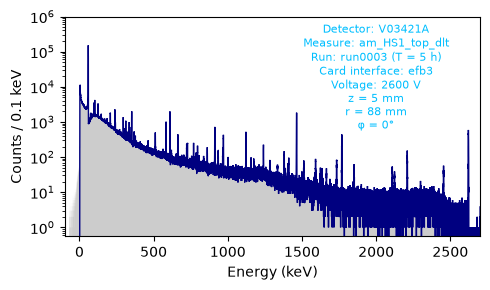

In [218]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)


plt.stairs(
    counts_data,
    bins,
    fill = True,
    color='grey',
    alpha = 0.4
)
'''
plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
'''
plt.stairs(
    counts_clean,
    bins,
    #fill = True,
    color='navy',
)

plt.annotate(
    annotation_measure,
    xy=(0.75, 0.97),
    xycoords="axes fraction",
    ha="center",
    va="top",
    multialignment="center",
    fontsize=8,
    zorder=8,
    color="deepskyblue",
)

# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(0, 1e6)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(-100, 2700)
plt.tight_layout()
plt.show()

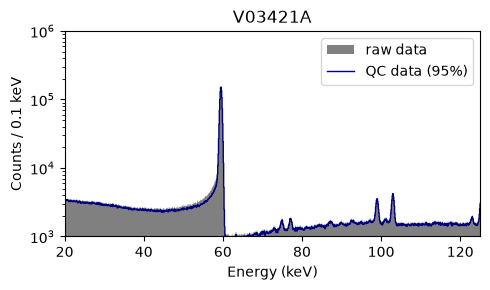

In [219]:
# ============================================================
# PLOT
# ============================================================
plt.figure(figsize=(5, 3))#, dpi = 300)


plt.stairs(
    counts_data,
    bins,
    fill = True,
    color='grey',

    label = f'raw data'
)
'''
plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
'''
plt.stairs(
    counts_clean,
    bins,
    #fill = True,
    color='navy',
    label = f'QC data ({np.sum(counts_clean)/ np.sum(counts_data)*100:.0f}%)'
)


# axvline non modifica i limiti verticali del grafico
#for energy in peaks.values():
#    plt.axvline(energy, color="red", linewidth=0.8)

#plt.axvline(2615, color="red", linewidth=0.8)

plt.yscale("log")
plt.ylim(1000, 1e6)
plt.ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
plt.xlabel("Energy (keV)")
plt.xlim(20, 125)
plt.title(detector)
plt.tight_layout()
plt.legend()
plt.show()

In [220]:
print( Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector)

/global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A


In [221]:
bkg_tak

'3'

In [222]:
bkg_run = f'run000{bkg_tak}'
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
    / bkg_run
)

energy_path = folder / f"{detector}_bkg_{bkg_run}_e_cal.npy"

if not energy_path.is_file():
    raise FileNotFoundError(
        f"Energie calibrate non trovate:\n{energy_path}\n"
        f"File disponibili: {[p.name for p in folder.glob('*')]}"
    )

# mmap evita di caricare subito tutto il file in memoria.
energy_bkg_cal = np.load(
    energy_path,
    mmap_mode="r",
    allow_pickle=False,
)

print(f"File: {energy_path}")
print(f"Eventi: {energy_bkg_cal.size:,}")


File: /global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A/run0003/V03421A_bkg_run0003_e_cal.npy
Eventi: 6,021,455


In [223]:
import json
path = folder / f"{detector}_bkg_{bkg_run}_calibration.json"

with path.open(encoding="utf-8") as stream:
    calibration = json.load(stream)

# Dizionario completo.
#display(calibration);

# Coefficienti: E_cal = a0 + a1 * E_input + a2 * E_input**2
a0, a1, a2 = calibration["coefficients"]

print(f"a0 = {a0:.10g}")
print(f"a1 = {a1:.10g}")
print(f"a2 = {a2:.10g}")

a0 = 0.02434918937
a1 = 0.5430557594
a2 = 8.091018112e-08


In [224]:
bins

array([ -70. ,  -69.9,  -69.8, ..., 2999.8, 2999.9, 3000. ],
      shape=(30701,))

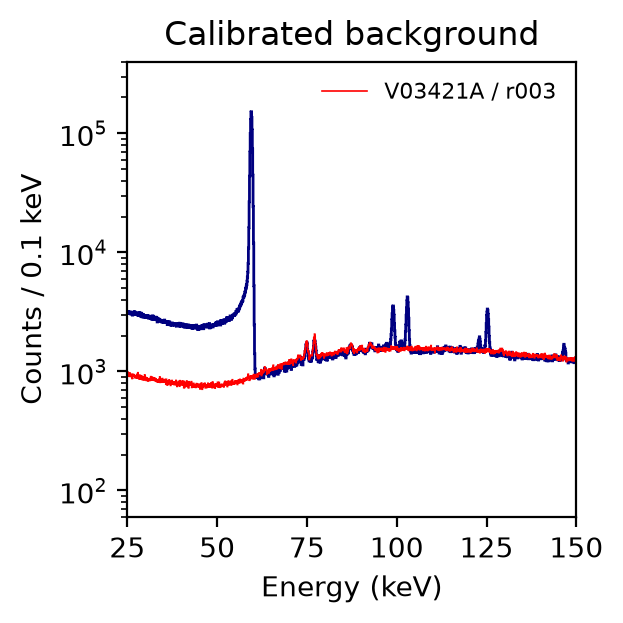

In [226]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
)
'''
plt.stairs(
    counts_data,
    bins,
    color="deepskyblue",
    ls = '--',
    zorder = 10
)'''

ax.stairs(
    counts_bkg * alpha,
    bins,
    color="red",
    linewidth=0.6,
    #ls = '--',
    label=f"{detector} / {run_tag}",
)



ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(25,150)
ax.set_ylim(6e1, 4e5)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.set_title("Calibrated background")
ax.legend(frameon=False, fontsize=8)

plt.show()

# counting method

In [227]:
pattern = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    "prodenv/ref/v1.2.1/generated/par/hit/"
    f"{detector}/c1/am_HS1_lat_dlt/*.yaml"
)

files_par = sorted(glob.glob(pattern))

if not files_par:
    raise FileNotFoundError(f"Nessun file trovato: {pattern}")

print(f"File trovati: {len(files_par)}")

# Carica tutti i YAML: una voce per ogni file.
parameters_by_file = {}

for filename in files_par:
    with open(filename, encoding="utf-8") as stream:
        parameters_by_file[filename] = yaml.safe_load(stream)

    print(filename)

File trovati: 1
/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/par/hit/V03421A/c1/am_HS1_lat_dlt/char_data-V03421A-am_HS1_lat_dlt-r001-20240324T201613Z-par_hit.yaml


In [228]:
par = parameters_by_file[files_par[0]]
print(par.keys())

dict_keys(['pars', 'results'])


In [229]:
par['pars']['operations']

{'bl_pileup_cut_classifier': {'expression': '((baselineEmax)-a)/b',
  'parameters': {'a': 12.84509375661051, 'b': 2.212708146651797}},
 'bl_pileup_cut': {'expression': '(bl_pileup_cut_classifier>a) & (bl_pileup_cut_classifier<b)',
  'parameters': {'a': -4, 'b': 4}},
 'tail_pileup_cut_classifier': {'expression': '((tailEmax)-a)/b',
  'parameters': {'a': 12.756106800766949, 'b': 2.2905651003949634}},
 'tail_pileup_cut': {'expression': '(tail_pileup_cut_classifier>a) & (tail_pileup_cut_classifier<b)',
  'parameters': {'a': -4, 'b': 4}},
 'is_valid_bl_slope_classifier': {'expression': '((bl_slope)-a)/b',
  'parameters': {'a': 0.01905524820192607, 'b': 0.029166420648803218}},
 'is_valid_bl_slope': {'expression': '(is_valid_bl_slope_classifier>a) & (is_valid_bl_slope_classifier<b)',
  'parameters': {'a': -5, 'b': 5}},
 'is_valid_bl_slope_rms_classifier': {'expression': '((bl_slope_rms)-a)/b',
  'parameters': {'a': 9.230980844615852, 'b': 0.4595154723425604}},
 'is_valid_bl_slope_rms': {'expr

In [230]:
def extract_sigma(E):
    a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["a"]

    b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["b"]
    
    c = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["c"]
    
    return    (a+b*E+c*E**2)**(0.5)/2.355
    

In [231]:
extract_sigma(59.5)

0.2779058694554556

In [232]:
bc = (bins[1:] + bins[:-1])*0.5


e_left_low , e_left_high = (56.5, 57.5)
mask_left = (bc >= e_left_low) & (bc <= e_left_high )
e_right_low, e_rigth_high = (61.5, 62.5)
mask_right = (bc >= e_right_low) & (bc <= e_rigth_high )

sigma = extract_sigma(59.5)
p1 = 59.5
peak_range = (p1 - 3 * sigma, p1 + 3 * sigma )
mask_peak = (bc >= peak_range[0]) & (bc <= peak_range[1])

In [233]:
count_left = np.sum(counts_clean[mask_left])
count_right = np.sum(counts_clean[mask_right])
counts_peak = np.sum(counts_clean[mask_peak])

In [234]:

sigma_peak = np.sum(np.sqrt(counts_clean[mask_peak]))
sigma_left = np.sum(np.sqrt(counts_clean[mask_left])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
sigma_right = np.sum(np.sqrt(counts_clean[mask_right])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

# uncorrelated ucertainties
sigma_tot = sigma_peak - (sigma_left + sigma_right)

print(sigma_tot)

2910.301385755285


In [235]:
counts_net = counts_peak - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

print('left tail count', count_left)
print('right tail count', count_right)
print('peak count', counts_peak)
print('net peak count', counts_net, '+/-', int(sigma_tot),',', int(counts_net/counts_peak *100), '%')

left tail count 39236
right tail count 9015
peak count 1101615
net peak count 1053364.0 +/- 2910 , 95 %


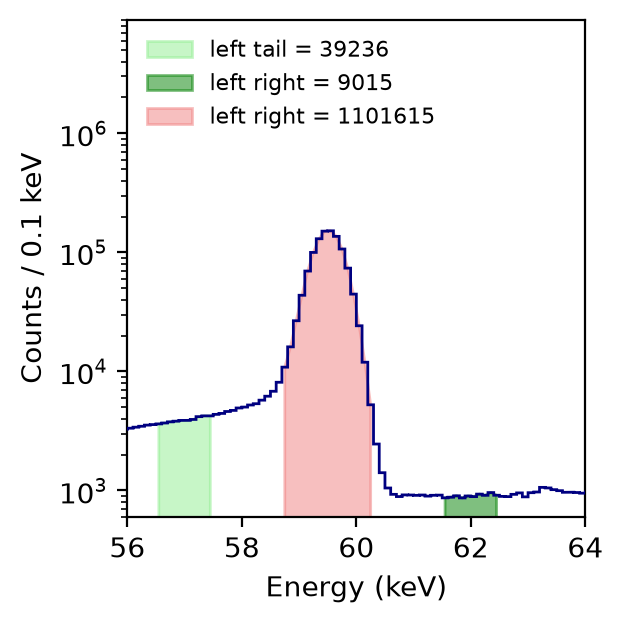

In [236]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
    zorder = 10
)

plt.fill_between(bc[mask_left] , counts_clean[mask_left] , color = 'lightgreen', alpha = 0.5,  label = f'left tail = {count_left} ')
plt.fill_between(bc[mask_right] , counts_clean[mask_right] , color = 'green',  alpha = 0.5, label = f'left right = {count_right} ')
plt.fill_between(bc[mask_peak] , counts_clean[mask_peak] , color = 'lightcoral', alpha = 0.5 , label = f'left right = {counts_peak} ')


ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(56,64)
ax.set_ylim(6e2, 9e6)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.legend(frameon=False, fontsize=8, loc = 'upper left')

plt.show()

In [237]:
bc = (bins[1:] + bins[:-1])*0.5


e_left_low , e_left_high = (94,96)
mask_left = (bc >= e_left_low) & (bc <= e_left_high )
e_right_low, e_rigth_high = (105, 107)
mask_right = (bc >= e_right_low) & (bc <= e_rigth_high )


p1 = 99
sigma = extract_sigma(p1)
peak_range1 = (p1 - 3 * sigma, p1 + 3 * sigma )
mask_peak1 = (bc >= peak_range1[0]) & (bc <= peak_range1[1])
p2 = 103
sigma = extract_sigma(p2)
peak_range2 = (p2 - 3 * sigma, p2 + 3 * sigma )
mask_peak2 = (bc >= peak_range2[0]) & (bc <= peak_range2[1])

In [238]:
count_left = np.sum(counts_clean[mask_left])
count_right = np.sum(counts_clean[mask_right])
counts_peak1 = np.sum(counts_clean[mask_peak1])
counts_peak2 = np.sum(counts_clean[mask_peak2])

In [239]:
counts_net1 = counts_peak1 - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
counts_net2 = counts_peak2 - (count_left + count_right )/((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

print('left tail count', count_left)
print('right tail count', count_right)
print('peak count 99 keV', counts_peak1)
print('peak count 103 keV', counts_peak2)
print('net peak count 99 keV', counts_net1)
print('net peak count 103 keV', counts_net2) #, '+/-', int(sigma_tot),',', int(counts_net/counts_peak *100), '%')

left tail count 31141
right tail count 29554
peak count 99 keV 43661
peak count 103 keV 47192
net peak count 99 keV 13313.5
net peak count 103 keV 16844.5


In [240]:

sigma_peak1 = np.sum(np.sqrt(counts_clean[mask_peak1]))
sigma_peak2 = np.sum(np.sqrt(counts_clean[mask_peak2]))
sigma_left = np.sum(np.sqrt(counts_clean[mask_left])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))
sigma_right = np.sum(np.sqrt(counts_clean[mask_right])) / ((e_left_high - e_left_high) + (e_rigth_high - e_right_low))

# uncorrelated ucertainties
sigma_tot1 = sigma_peak1 - (sigma_left + sigma_right)
sigma_tot2 = sigma_peak2 - (sigma_left + sigma_right)
print(sigma_tot1)
print(sigma_tot2)

98.673342910021
128.14499312454245


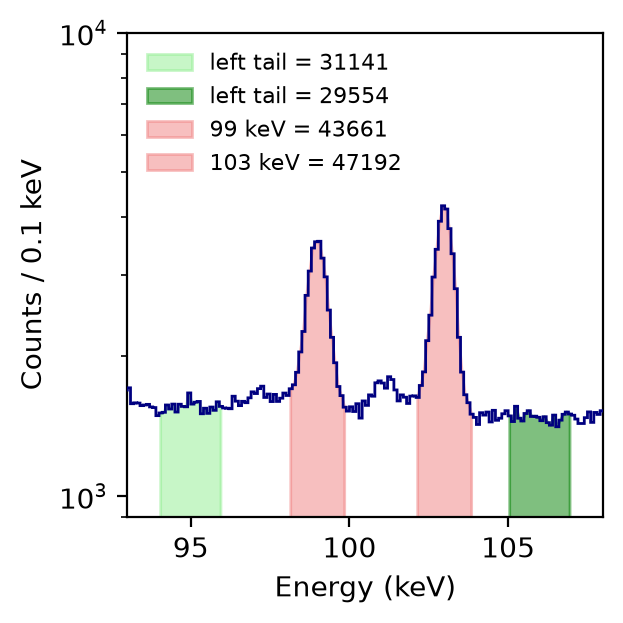

In [241]:

# ============================================================
# HISTOGRAM — 1 keV BINS
# ============================================================

#bins_bkg = np.linspace(0, 3500, 3501)

counts_bkg, _ = np.histogram(
    energy_bkg_cal,
    bins=bins,
)
bins
fig, ax = plt.subplots(
    figsize=(3,3),
    dpi=200,
    layout="constrained",
)

plt.stairs(
    counts_clean,
    bins,
    color="navy",
    zorder = 10
)

plt.fill_between(bc[mask_left] , counts_clean[mask_left] , color = 'lightgreen', alpha = 0.5,  label = f'left tail = {count_left} ')
plt.fill_between(bc[mask_right] , counts_clean[mask_right] , color = 'green',  alpha = 0.5, label = f'left tail = {count_right} ')
plt.fill_between(bc[mask_peak1] , counts_clean[mask_peak1] , color = 'lightcoral', alpha = 0.5 , label = f'99 keV = {counts_peak1} ')
plt.fill_between(bc[mask_peak2] , counts_clean[mask_peak2] , color = 'lightcoral', alpha = 0.5 , label = f'103 keV = {counts_peak2} ')


ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(93, 108)
ax.set_ylim(9e2, 1e4)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
ax.legend(frameon=False, fontsize=8, loc = 'upper left')

plt.show()



# fit by Vale


In [242]:
import numpy as np

from scipy.special import erfc
from scipy.stats import chi2

from pygama.math import binned_fitting as pgb
from pygama.math import distributions as pgf


# ============================================================
# PARAMETER ORDER
# ============================================================

NAMES60 = [
    "N60", "mu60", "sigma60",
    "N60_tail", "tau60",
    "B60", "S60",
]

NAMES100 = [
    "N99", "mu99", "sigma99",
    "N103", "mu103", "sigma103",
    "N101", "mu101", "sigma101",
    "B100", "S100",
]

FWHM_FACTOR = 2.354820045



In [309]:
import builtins

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import erfc
from scipy.stats import chi2

from pygama.math import binned_fitting as pgb
from pygama.math import distributions as pgf


def fit_am_peak(
    counts,
    bins,
    region="60",
    sample="data",
    variance=None,
    fit_range=None,
    detector=None,
    plot=True,
    log_scale=True,
):
    """
    Sigma fissate tramite la funzione esterna extract_sigma(E).

    60 keV:
        Gaussiana + coda sinistra + step + fondo.

    100 keV, data:
        Tre gaussiane (99, 101, 103 keV)
        + due step di uguale altezza + fondo.

    100 keV, MC:
        Due gaussiane (99, 103 keV)
        + un solo step a 103 keV + fondo.

    Parametrizzazione del continuo:
        B = fondo a destra, in counts/keV.
        S = incremento relativo, adimensionale.
        Altezza di ogni step = B * S.

    Per MC pesato:
        variance = somma dei pesi² per bin.

    Non viene sottratto alcun background.
    """

    region = str(region)
    sample = str(sample).lower()

    if region not in ("60", "100"):
        raise ValueError("region deve essere '60' oppure '100'.")

    if sample not in ("data", "mc"):
        raise ValueError("sample deve essere 'data' oppure 'MC'.")

    counts = np.asarray(counts, dtype=float)
    bins = np.asarray(bins, dtype=float)

    if (
        counts.ndim != 1
        or bins.ndim != 1
        or counts.size == 0
        or bins.size != counts.size + 1
    ):
        raise ValueError("Dimensioni dell'istogramma non valide.")

    if not np.isfinite(counts).all() or np.any(counts < 0):
        raise ValueError("Servono conteggi finiti e non negativi.")

    if (
        not np.isfinite(bins).all()
        or np.any(np.diff(bins) <= 0)
    ):
        raise ValueError("Bordi dei bin non validi.")

    # ========================================================
    # VARIANCE
    # ========================================================

    if variance is None:
        if sample == "mc":
            raise ValueError(
                "Per MC specifica variance: counts per MC non "
                "pesato, oppure somma dei pesi² per MC pesato."
            )

        variance = counts.copy()

    variance = np.asarray(variance, dtype=float)

    if variance.shape != counts.shape:
        raise ValueError(
            f"Shape diverse: counts={counts.shape}, "
            f"variance={variance.shape}."
        )

    if (
        not np.isfinite(variance).all()
        or np.any(variance < 0)
    ):
        raise ValueError("Varianze non finite o negative.")

    invalid = (counts > 0) & (variance == 0)

    if np.any(invalid):
        raise ValueError(
            f"{np.count_nonzero(invalid)} bin hanno conteggi "
            "positivi ma varianza zero."
        )

    # ========================================================
    # FIT WINDOW
    # ========================================================

    if fit_range is None:
        fit_range = (
            (57.0, 64.0)
            if region == "60"
            else (95.0, 107)
        )

    xmin, xmax = fit_range

    if not np.isfinite([xmin, xmax]).all() or xmin >= xmax:
        raise ValueError("Finestra di fit non valida.")

    selected = np.flatnonzero(
        (bins[:-1] >= xmin - 1e-9)
        & (bins[1:] <= xmax + 1e-9)
    )

    if selected.size == 0:
        raise ValueError("Nessun bin nella finestra di fit.")

    first = selected[0]
    last = selected[-1] + 1

    edges = bins[first:last + 1]
    y = counts[first:last]
    var = variance[first:last]

    widths = np.diff(edges)

    if not np.allclose(widths, widths[0]):
        raise ValueError("Servono bin uniformi.")

    width = builtins.float(widths[0])
    centers = (edges[:-1] + edges[1:]) / 2

    background_guess = builtins.float(
        np.maximum(
            np.percentile(y / width, 10),
            1e-3,
        )
    )

    # ========================================================
    # HELPERS
    # ========================================================

    def fixed_sigma(energy):
        sigma = builtins.float(extract_sigma(energy))

        if not np.isfinite(sigma) or sigma <= 0:
            raise ValueError(
                f"Sigma non valida a {energy:g} keV: {sigma}"
            )

        return sigma

    def area_guess(mu, sigma):
        index = np.argmin(np.abs(centers - mu))

        height = np.maximum(
            y[index] / width - background_guess,
            1.0,
        )

        return height * np.sqrt(2 * np.pi) * sigma

    def step_density(x, mu, sigma, background, relative_step):
        """
        Componente dello step, in counts/keV.

        A sinistra tende a B*S.
        A destra tende a zero.

        Sommando il fondo costante B:
            sinistra -> B*(1+S)
            destra   -> B
        """
        return (
            background
            * relative_step
            * 0.5
            * erfc(
                (x - mu) / (np.sqrt(2) * sigma)
            )
        )

    # ========================================================
    # 60 keV — DATA AND MC
    # ========================================================

    if region == "60":
        sigma60 = fixed_sigma(59.5)

        fixed_sigmas = {"60": sigma60}
        sigma_energies = {"60": 59.5}

        names = [
            "N60", "mu60",
            "N60_tail", "tau60",
            "B60", "S60",
        ]

        area = area_guess(59.5, sigma60)

        p0 = [
            area, 59.5,
            area * 0.1, 1.0,
            background_guess, 0.5,
        ]

        limits = [
            (0, None), (58.8, 60.3),
            (0, None), (0.02, 10),
            (0, None), (0, None),
        ]

        def density(x, p):
            x = np.asarray(x, dtype=float)

            n, mu, nt, tau, bg, step = p

            out = {
                "gaussian_60": (
                    n * pgf.gaussian.get_pdf(
                        x, mu, sigma60
                    )
                ),
                "tail": (
                    nt * pgf.exgauss.get_pdf(
                        x, mu, sigma60, tau
                    )
                ),
                "step_60": step_density(
                    x, mu, sigma60, bg, step
                ),
                "background": np.full_like(x, bg),
            }

            out["total"] = builtins.sum(out.values())
            return out

        def model(
            x,
            N60, mu60,
            N60_tail, tau60,
            B60, S60,
        ):
            return width * density(
                x,
                (
                    N60, mu60,
                    N60_tail, tau60,
                    B60, S60,
                ),
            )["total"]

        area_indices = {"60": 0}

    # ========================================================
    # 100 keV — DATA
    # ========================================================

    elif sample == "data":
        small_mu = (
            100.5 if detector == "V08682A" else 101.0
        )

        sigma99 = fixed_sigma(99.0)
        sigma101 = fixed_sigma(small_mu)
        sigma103 = fixed_sigma(103.0)

        fixed_sigmas = {
            "99": sigma99,
            "101": sigma101,
            "103": sigma103,
        }

        sigma_energies = {
            "99": 99.0,
            "101": small_mu,
            "103": 103.0,
        }

        names = [
            "N99", "mu99",
            "N103", "mu103",
            "N101", "mu101",
            "B100", "S100",
        ]

        p0 = [
            area_guess(99.0, sigma99), 99.0,
            area_guess(103.0, sigma103), 103.0,
            area_guess(small_mu, sigma101) * 0.1,
            small_mu,
            background_guess, 0.5,
        ]

        limits = [
            (0, None), (98.5, 99.5),
            (0, None), (102.5, 103.5),
            (0, None), (100.0, 101.6),
            (0, None), (0, None),
        ]

        def density(x, p):
            x = np.asarray(x, dtype=float)

            (
                n99, m99,
                n103, m103,
                n101, m101,
                bg, step,
            ) = p

            out = {
                "gaussian_99": (
                    n99 * pgf.gaussian.get_pdf(
                        x, m99, sigma99
                    )
                ),
                "gaussian_103": (
                    n103 * pgf.gaussian.get_pdf(
                        x, m103, sigma103
                    )
                ),
                "gaussian_101": (
                    n101 * pgf.gaussian.get_pdf(
                        x, m101, sigma101
                    )
                ),
                "step_99": step_density(
                    x, m99, sigma99, bg, step
                ),
                "step_103": step_density(
                    x, m103, sigma103, bg, step
                ),
                "background": np.full_like(x, bg),
            }

            out["total"] = builtins.sum(out.values())
            return out

        def model(
            x,
            N99, mu99,
            N103, mu103,
            N101, mu101,
            B100, S100,
        ):
            return width * density(
                x,
                (
                    N99, mu99,
                    N103, mu103,
                    N101, mu101,
                    B100, S100,
                ),
            )["total"]

        area_indices = {
            "99": 0,
            "103": 2,
            "101": 4,
        }

    # ========================================================
    # 100 keV — MC: TWO GAUSSIANS, ONE STEP
    # ========================================================

    else:
        sigma99 = fixed_sigma(99.0)
        sigma103 = fixed_sigma(103.0)

        fixed_sigmas = {
            "99": sigma99,
            "103": sigma103,
        }

        sigma_energies = {
            "99": 99.0,
            "103": 103.0,
        }

        names = [
            "N99", "mu99",
            "N103", "mu103",
            "B100", "S100",
        ]

        p0 = [
            area_guess(99.0, sigma99), 99.0,
            area_guess(103.0, sigma103), 103.0,
            background_guess, 0.5,
        ]

        limits = [
            (0, None), (98.5, 99.5),
            (0, None), (102.5, 103.5),
            (0, None), (0, None),
        ]

        def density(x, p):
            x = np.asarray(x, dtype=float)

            (
                n99, m99,
                n103, m103,
                bg, step,
            ) = p

            out = {
                "gaussian_99": (
                    n99 * pgf.gaussian.get_pdf(
                        x, m99, sigma99
                    )
                ),
                "gaussian_103": (
                    n103 * pgf.gaussian.get_pdf(
                        x, m103, sigma103
                    )
                ),
                "step_103": step_density(
                    x, m103, sigma103, bg, step
                ),
                "background": np.full_like(x, bg),
            }

            out["total"] = builtins.sum(out.values())
            return out

        def model(
            x,
            N99, mu99,
            N103, mu103,
            B100, S100,
        ):
            return width * density(
                x,
                (
                    N99, mu99,
                    N103, mu103,
                    B100, S100,
                ),
            )["total"]

        area_indices = {
            "99": 0,
            "103": 2,
        }

    # ========================================================
    # FIT WITH PYGAMA
    # ========================================================

    used = var > 0
    n_parameters = len(p0)

    if np.count_nonzero(used) <= n_parameters:
        raise ValueError(
            "Troppi pochi bin con varianza positiva."
        )

    coefficients, fit_errors, cov = pgb.fit_binned(
        func=model,
        hist=y,
        bins=edges,
        var=var,
        guess=np.asarray(p0, dtype=float),
        cost_func="Least Squares",
        extended=True,
        bounds=dict(zip(names, limits)),
    )

    parameters = np.asarray(
        list(coefficients),
        dtype=float,
    )

    errors = np.asarray(
        list(fit_errors),
        dtype=float,
    )

    covariance = (
        np.asarray(cov, dtype=float)
        if cov is not None
        else np.full(
            (n_parameters, n_parameters),
            np.nan,
        )
    )

    expected = model(centers, *parameters)

    if (
        not np.isfinite(parameters).all()
        or not np.isfinite(expected).all()
        or np.any(expected < 0)
    ):
        raise RuntimeError("Risultato del fit non valido.")

    residuals = np.full_like(y, np.nan)

    residuals[used] = (
        (y[used] - expected[used])
        / np.sqrt(var[used])
    )

    chi_square = builtins.float(
        np.sum(residuals[used] ** 2)
    )

    ndof = int(
        np.count_nonzero(used) - n_parameters
    )

    p_value = builtins.float(
        chi2.sf(chi_square, ndof)
    )

    active_mask = np.zeros(
        n_parameters,
        dtype=int,
    )

    for index, (lower, upper) in enumerate(limits):
        if lower is not None and np.isclose(
            parameters[index],
            lower,
            atol=1e-7,
            rtol=1e-5,
        ):
            active_mask[index] = -1

        if upper is not None and np.isclose(
            parameters[index],
            upper,
            atol=1e-7,
            rtol=1e-5,
        ):
            active_mask[index] = 1

    # ========================================================
    # BACKGROUND LEVELS AND PROPAGATED ERRORS
    # ========================================================

    background_name = (
        "B60" if region == "60" else "B100"
    )
    step_name = (
        "S60" if region == "60" else "S100"
    )

    index_b = names.index(background_name)
    index_s = names.index(step_name)

    b_value = parameters[index_b]
    s_value = parameters[index_s]

    def derived_error(gradient):
        if not np.isfinite(covariance).all():
            return None

        variance_value = builtins.float(
            gradient @ covariance @ gradient
        )

        if variance_value < 0:
            return None

        return builtins.float(
            np.sqrt(variance_value)
        )

    # Altezza di ogni step: B*S.
    gradient_step = np.zeros(n_parameters)
    gradient_step[index_b] = s_value
    gradient_step[index_s] = b_value

    # Fondo a destra: B.
    gradient_right = np.zeros(n_parameters)
    gradient_right[index_b] = 1.0

    # Per i dati a 100 keV ci sono due step.
    number_of_steps = (
        2
        if region == "100" and sample == "data"
        else 1
    )

    # Fondo all'estrema sinistra: B*(1 + n_steps*S).
    gradient_left = np.zeros(n_parameters)
    gradient_left[index_b] = (
        1.0 + number_of_steps * s_value
    )
    gradient_left[index_s] = (
        number_of_steps * b_value
    )

    background_levels = {
        "right": {
            "value": b_value,
            "error": derived_error(gradient_right),
        },
        "step_height": {
            "value": b_value * s_value,
            "error": derived_error(gradient_step),
        },
        "left": {
            "value": (
                b_value
                * (1.0 + number_of_steps * s_value)
            ),
            "error": derived_error(gradient_left),
        },
    }

    if number_of_steps == 2:
        gradient_middle = np.zeros(n_parameters)
        gradient_middle[index_b] = 1.0 + s_value
        gradient_middle[index_s] = b_value

        background_levels["between_peaks"] = {
            "value": b_value * (1.0 + s_value),
            "error": derived_error(gradient_middle),
        }

    # ========================================================
    # RESULT DICTIONARY
    # ========================================================

    result = {
        "region": region,
        "sample": sample,
        "parameter_names": names,
        "parameter_order": names,
        "parameters": parameters,
        "errors": errors,
        "covariance": covariance,
        "area_indices": area_indices,

        "areas": {
            label: {
                "value": parameters[index],
                "error": errors[index],
            }
            for label, index in area_indices.items()
        },

        "fixed_sigmas": fixed_sigmas,
        "sigma_reference_energies_keV": sigma_energies,

        "fwhm_peaks": {
            label: {
                "value": 2.354820045 * sigma,
                "error": None,
                "fixed": True,
            }
            for label, sigma in fixed_sigmas.items()
        },

        "background_levels": background_levels,
        "background_units": "counts/keV",
        "step_parameter_definition": (
            "S is dimensionless; step height = B*S"
        ),

        "edges": edges,
        "counts": y,
        "variance": var,

        "components": {
            key: value * width
            for key, value in density(
                centers,
                parameters,
            ).items()
        },

        "residuals": residuals,
        "chi_square": chi_square,
        "ndof": ndof,
        "reduced_chi_square": chi_square / ndof,
        "p_value": p_value,
        "at_bounds": bool(np.any(active_mask)),
        "active_mask": active_mask,
        "figure": None,
    }

    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"\n{sample.upper()} — regione {region} keV"
    )

    for label, sigma in fixed_sigmas.items():
        print(
            f"sigma{label:7s} = "
            f"{sigma:.6g} keV — fissata"
        )

    for name, value, error in zip(
        names,
        parameters,
        errors,
    ):
        print(
            f"{name:12s} = "
            f"{value:.6g} ± {error:.3g}"
        )

    print("\nLivelli asintotici del continuo:")

    for name, item in background_levels.items():
        value = item["value"]
        error = item["error"]

        if error is None:
            print(
                f"{name:15s} = "
                f"{value:.6g} counts/keV"
            )
        else:
            print(
                f"{name:15s} = "
                f"{value:.6g} ± {error:.3g} counts/keV"
            )

    print(
        f"\nChi² / ndof = "
        f"{chi_square:.2f} / {ndof}"
    )
    print(
        f"Chi² ridotto = {chi_square / ndof:.3f}"
    )
    print(f"p-value = {p_value:.4g}")

    if result["at_bounds"]:
        print(
            "Attenzione: almeno un parametro è al limite."
        )

    # ========================================================
    # OPTIONAL PLOT
    # ========================================================

    if plot:
        fig, (ax, ax_res) = plt.subplots(
            2,
            1,
            figsize=(8, 4),
            sharex=True,
            height_ratios=[3, 1],
            layout="constrained",
            dpi=200,
        )

        x = np.linspace(
            edges[0],
            edges[-1],
            4000,
        )

        smooth = density(x, parameters)

        ax.stairs(
            y,
            edges,
            color="navy",
            linewidth=0.8,
            label=sample.upper(),
            zorder=3,
        )

        styles = {
            "total": (
                "Total fit",
                "darkorange",
                "-",
            ),
            "gaussian_60": (
                "Gaussian 59.5 keV",
                "crimson",
                "--",
            ),
            "gaussian_99": (
                "Gaussian 99 keV",
                "crimson",
                "--",
            ),
            "gaussian_101": (
                "Gaussian 101 keV",
                "purple",
                "--",
            ),
            "gaussian_103": (
                "Gaussian 103 keV",
                "green",
                "--",
            ),
            "tail": (
                "Left tail",
                "green",
                "--",
            ),
            "step_60": (
                "Step contribution",
                "deepskyblue",
                ":",
            ),
            "step_99": (
                "Step contribution at 99 keV",
                "deepskyblue",
                ":",
            ),
            "step_103": (
                "Step contribution at 103 keV",
                "brown",
                ":",
            ),
            "background": (
                "Right background B",
                "gray",
                "--",
            ),
        }

        for key in ["total"] + [
            key
            for key in smooth
            if key != "total"
        ]:
            label, color, linestyle = styles[key]
            curve = smooth[key] * width

            if log_scale:
                curve = np.where(
                    curve > 0,
                    curve,
                    np.nan,
                )

            ax.plot(
                x,
                curve,
                color=color,
                linestyle=linestyle,
                linewidth=0.9,
                label=label,
            )

        # Continuo completo: fondo + step.
        continuum = smooth["background"].copy()

        for key, component in smooth.items():
            if key.startswith("step_"):
                continuum += component

        continuum_curve = continuum * width

        if log_scale:
            continuum_curve = np.where(
                continuum_curve > 0,
                continuum_curve,
                np.nan,
            )

        ax.plot(
            x,
            continuum_curve,
            color="black",
            linewidth=1.0,
            linestyle="-.",
            label="Continuum B + step(s)",
        )

        if log_scale:
            ax.set_yscale("log")

            positive = y[y > 0]

            if positive.size:
                ymax = np.maximum(
                    y.max(),
                    np.max(smooth["total"]) * width,
                )

                ax.set_ylim(
                    positive.min() * 0.3,
                    ymax * 3,
                )

        text_lines = [
            rf"$N_{{{label}}}={parameters[index]:.4g}"
            rf"\pm{errors[index]:.2g}$"
            for label, index in area_indices.items()
        ]

        text_lines += [
            rf"$\sigma_{{{label}}}={sigma:.4f}$ keV (fixed)"
            for label, sigma in fixed_sigmas.items()
        ]

        text_lines += [
            rf"$\chi^2/\nu={chi_square:.1f}/{ndof}$",
            rf"$p={p_value:.3g}$",
        ]

        ax.text(
            0.98,
            0.97,
            "\n".join(text_lines),
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=5.5,
            color="navy",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
            },
        )

        ax.set_title(
            f"{detector or ''} — "
            f"{sample.upper()} — {region} keV",
            fontsize=8,
        )

        ax.set_ylabel(
            f"Counts / {width:g} keV",
            fontsize=7,
        )

        ax.legend(
            frameon=False,
            fontsize=5,
            loc="upper left",
        )

        ax_res.axhline(
            0,
            color="gray",
            linestyle="--",
            linewidth=0.7,
        )

        ax_res.plot(
            centers[used],
            residuals[used],
            ".",
            color="navy",
            markersize=3,
        )

        ax_res.set_ylabel(
            "Fit\nresidual",
            fontsize=6,
        )

        ax_res.set_xlabel(
            "Energy (keV)",
            fontsize=7,
        )

        ax_res.set_xlim(
            edges[0],
            edges[-1],
        )

        for axis in (ax, ax_res):
            axis.tick_params(labelsize=6)

        result["figure"] = fig

        plt.show()

    return result


DATA — regione 60 keV
sigma60      = 0.277906 keV — fissata
N60          = 1.0223e+06 ± 1.78e+03
mu60         = 59.5169 ± 0.000397
N60_tail     = 73855.6 ± 1.91e+03
tau60        = 0.761402 ± 0.0457
B60          = 9228.39 ± 50.8
S60          = 2.84486 ± 0.097

Livelli asintotici del continuo:
right           = 9228.39 ± 50.8 counts/keV
step_height     = 26253.5 ± 872 counts/keV
left            = 35481.9 ± 870 counts/keV

Chi² / ndof = 187.28 / 64
Chi² ridotto = 2.926
p-value = 5.058e-14


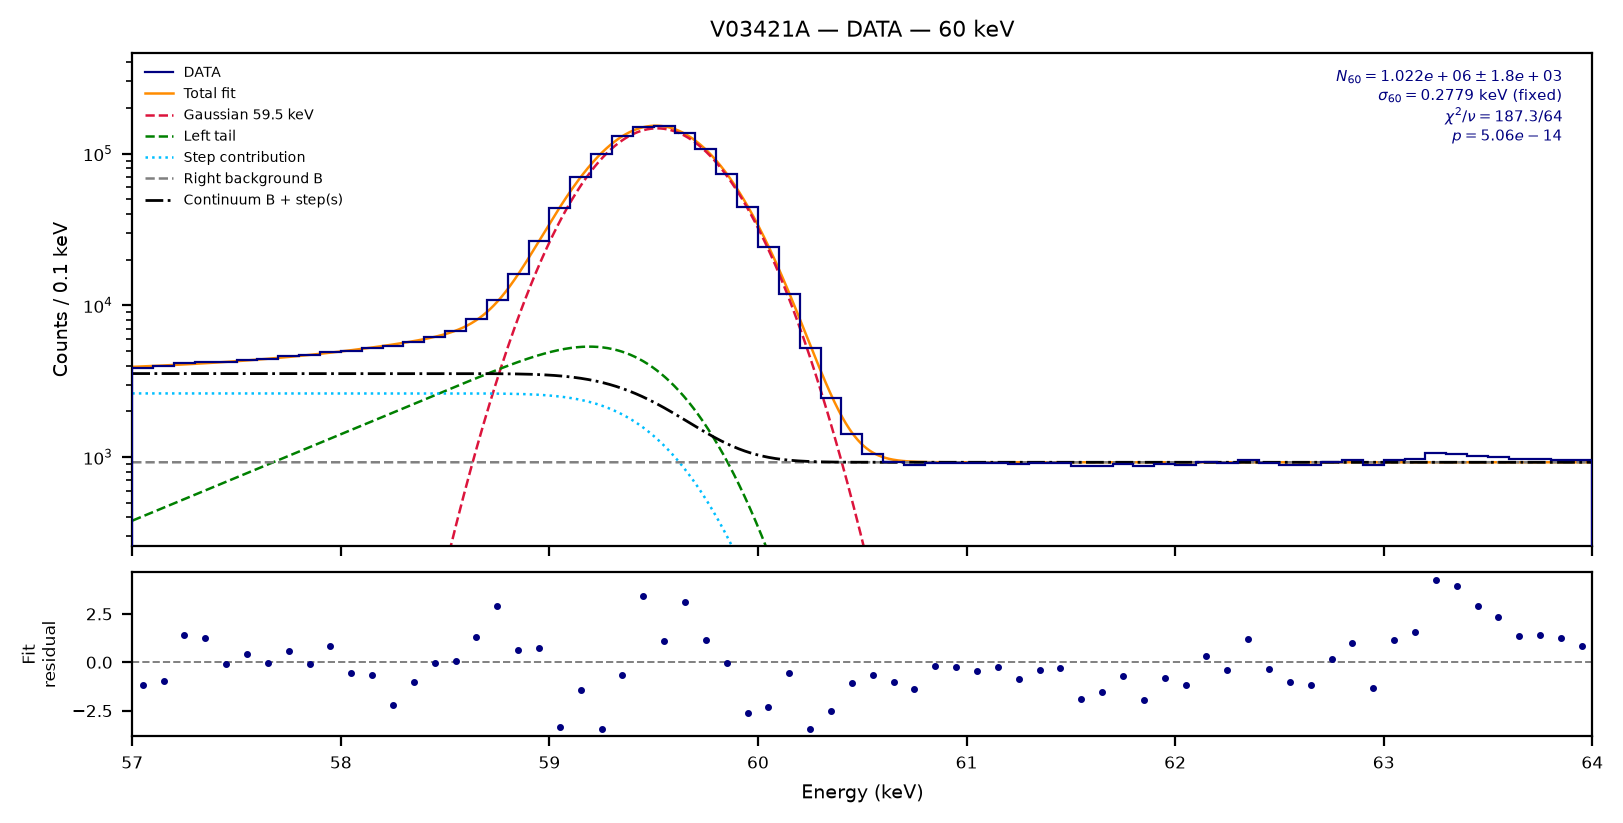


DATA — regione 100 keV
sigma99      = 0.300562 keV — fissata
sigma101     = 0.301664 keV — fissata
sigma103     = 0.302763 keV — fissata
N99          = 15201.9 ± 192
mu99         = 98.9877 ± 0.00475
N103         = 20126.1 ± 204
mu103        = 102.981 ± 0.00368
N101         = 1897.87 ± 144
mu101        = 101.148 ± 0.0337
B100         = 14790.7 ± 62.9
S100         = 0.0433275 ± 0.00338

Livelli asintotici del continuo:
right           = 14790.7 ± 62.9 counts/keV
step_height     = 640.842 ± 47.9 counts/keV
left            = 16072.3 ± 65.3 counts/keV
between_peaks   = 15431.5 ± 42.5 counts/keV

Chi² / ndof = 142.73 / 112
Chi² ridotto = 1.274
p-value = 0.02654


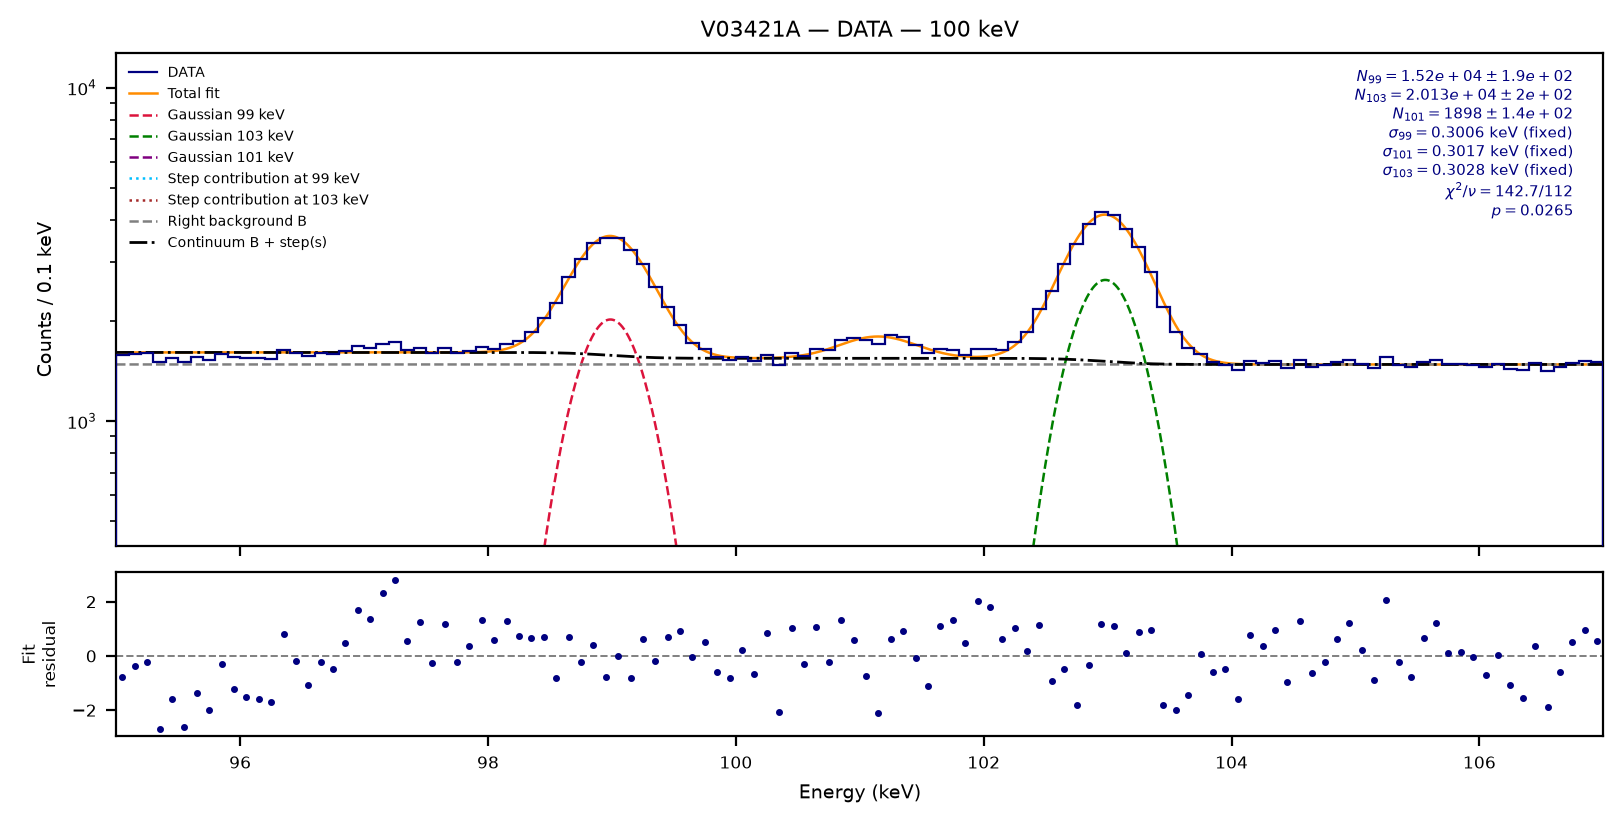

In [310]:
result60_data = fit_am_peak(
    counts_clean, bins,
    region="60",
    sample="data",
    detector=detector,
)

result100_data = fit_am_peak(
    counts_clean, bins,
    region="100",
    sample="data",
    detector=detector,
)

# A/E

In [247]:
files = (
    f"/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/"
    f"{version}/generated/tier/hit/{detector}/{campaign}/{measure}/*.lh5"
)
files_names = sorted(glob.glob(files))

In [259]:
hit = lh5.read(
            "hit",
            files_names,
        )

In [260]:
len(files_names)

90

In [261]:
blue = '#1A2A5B'
azzurro = '#07A9FF'
grigio = '#CCCCCC'

In [262]:
hit.keys()

dict_keys(['AoE_Classifier', 'AoE_Corrected', 'AoE_Double_Sided_Cut', 'AoE_High_Side_Cut', 'AoE_Low_Cut', 'LQ_Classifier', 'LQ_Cut', 'bl_pileup_cut', 'bl_pileup_cut_classifier', 'cuspEmax_cal', 'cuspEmax_ctc_cal', 'cuspEmax_noctc_cal', 'daqenergy_cal', 'dt_eff', 'is_discharge', 'is_downgoing_baseline', 'is_empty_candidate', 'is_highly_positive_polarity_candidate', 'is_low_cuspEmax', 'is_neg_energy', 'is_negative', 'is_negative_crosstalk_old', 'is_negative_polarity_candidate', 'is_noise_burst', 'is_not_noise_burst', 'is_positive_polarity_candidate', 'is_saturated', 'is_surface', 'is_upgoing_baseline', 'is_valid_0vbb_old', 'is_valid_baseline_old', 'is_valid_bl_slope', 'is_valid_bl_slope_classifier', 'is_valid_bl_slope_rms', 'is_valid_bl_slope_rms_classifier', 'is_valid_cal', 'is_valid_cuspEmax', 'is_valid_cuspEmax_classifier', 'is_valid_cuspEmin', 'is_valid_cuspEmin_classifier', 'is_valid_dteff', 'is_valid_dteff_old', 'is_valid_ediff', 'is_valid_efrac', 'is_valid_neg_current', 'is_valid_

In [264]:
aoe_raw = np.asarray(hit["AoE_Corrected"].nda)
ene_raw = np.asarray(hit["cuspEmax_ctc_cal"].nda)

is_discharge = np.asarray(
    hit["is_discharge"].nda,
    dtype=bool,
)
positive_bits = np.asarray(hit["is_positive_polarity_candidate"].nda)
mask = (~is_discharge) & ((positive_bits == 127) | (positive_bits == 63))

aoe = aoe_raw[mask]
ene = ene_raw[mask]

A/E di riferimento: 0.693031
Eventi nella finestra: 3,240,965


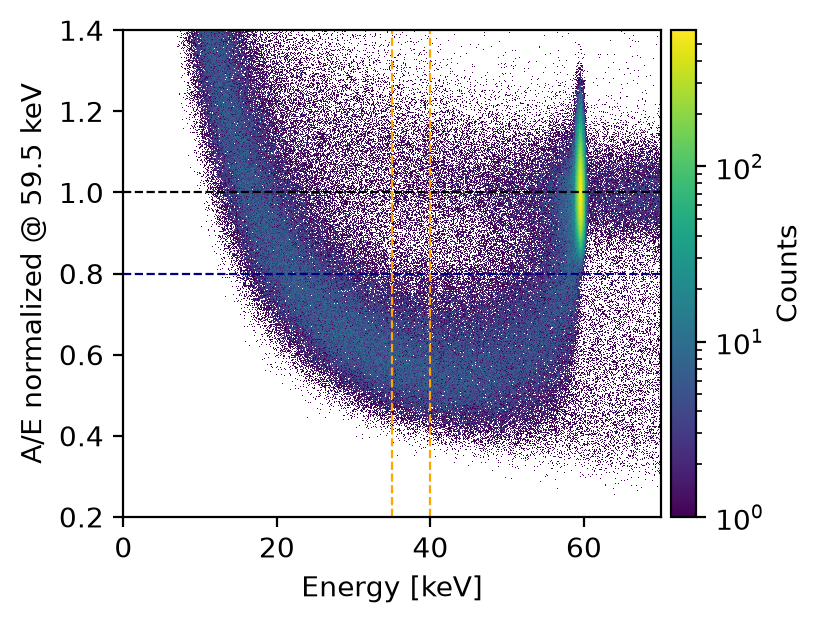

In [265]:
mask = np.isfinite(ene) & np.isfinite(aoe)


# Riferimento: eventi nella finestra 59–60 keV.
mask_60 = mask & (ene >= 59.5 - 3*extract_sigma(59.5)) & (ene < 59.5 + 3*extract_sigma(59.5))

if not np.any(mask_60):
    raise ValueError("Nessun evento nella finestra 59–60 keV.")

aoe_ref = np.median(aoe[mask_60])

if not np.isfinite(aoe_ref) or aoe_ref <= 0:
    raise ValueError("Riferimento A/E non valido.")

aoe_norm = aoe / aoe_ref

print(f"A/E di riferimento: {aoe_ref:.6g}")
print(f"Eventi nella finestra: {mask_60.sum():,}")

cut = 0.80
emin, emax = 0, 70
aoemin, aoemax = 0.2, 1.4

bins_ene = np.linspace(emin, emax, 701)
bins_aoe = np.arange(aoemin, aoemax + 0.00022, 0.00022)

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=200,
    layout="constrained",
)

cmap = plt.colormaps["viridis"].copy()
cmap.set_bad("white")

hist = ax.hist2d(
    ene[mask],
    aoe_norm[mask],
    bins=(bins_ene, bins_aoe),
    cmap=cmap,
    norm=LogNorm(),
    cmin=1,
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=0.8,
)
ax.axhline(
    cut,
    color="navy",
    linestyle="--",
    linewidth=0.8,
    label='cut'
)

ax.set_xlim(emin, emax)
ax.set_ylim(aoemin, aoemax)

ax.set_xlabel("Energy [keV]")
ax.set_ylabel("A/E normalized @ 59.5 keV")

#plt.axvline(30, color = 'orange',  lw = 0.8)
#plt.axvline(45, color = 'orange',  lw = 0.8)

plt.axvline(35, color = 'orange', ls = '--', lw = 0.8)
plt.axvline(40, color = 'orange', ls = '--', lw = 0.8)

cbar = fig.colorbar(
    hist[3],
    ax=ax,
    orientation="vertical",
    pad=0.02,
    fraction=0.05,
)

cbar.set_label("Counts")


(0.0, 1.4)

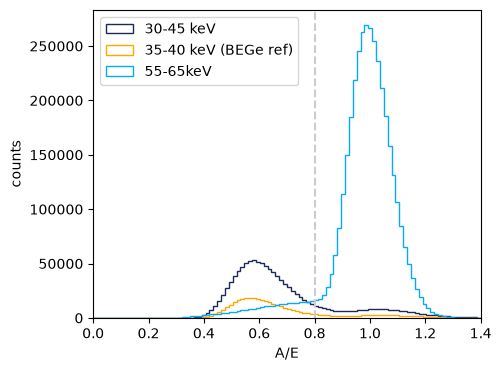

In [266]:
aoe_high = aoe_norm[(ene>55) & (ene <65)]
aoe_low = aoe_norm[(ene>30) & (ene <45)]
aoe_cenetr = aoe_norm[(ene>35) & (ene <40)]
min, max = (0, 1.4)
plt.figure(figsize = (5,4))
#plt.hist(aoe_norm, bins = 100, range = (min, max ), color = grigio, )
plt.hist(aoe_low,  bins =100 ,range = (min, max ), histtype = 'step',  color = blue, label = '30-45 keV')
#plt.hist(aoe_norm[(ene>30) & (ene <45)],  bins =100 ,range = (min, max ), histtype = 'step', ls = '--',  color = 'navy', label = '30-45 keV')
plt.hist(aoe_cenetr,  bins =100 ,range = (min, max ), histtype = 'step',  color = 'orange', label = '35-40 keV (BEGe ref)')
plt.hist(aoe_high,   bins = 100, range = (min, max ), histtype = 'step', color = azzurro, label = '55-65keV')
plt.axvline(cut, color = grigio, ls = '--')
#plt.yscale('log')
plt.xlabel('A/E')
plt.ylabel('counts')
plt.legend()
plt.xlim(0,1.4)

In [267]:


print(f'SP franction (30-45 keV) = {np.sum(aoe_low[(aoe_low>0.2) & (aoe_low<cut)]) / np.sum(aoe_high[(aoe_high>cut) & (aoe_high<1.25)])*100 :.0f} %')

print(f'SP franction (35-40 keV) = {np.sum(aoe_cenetr[(aoe_cenetr>0.2) & (aoe_cenetr<cut)]) / np.sum(aoe_high[(aoe_high>cut) & (aoe_high<1.25)])*100 :.0f} %')



SP franction (30-45 keV) = 15 %
SP franction (35-40 keV) = 5 %


(5.0, 80.0)

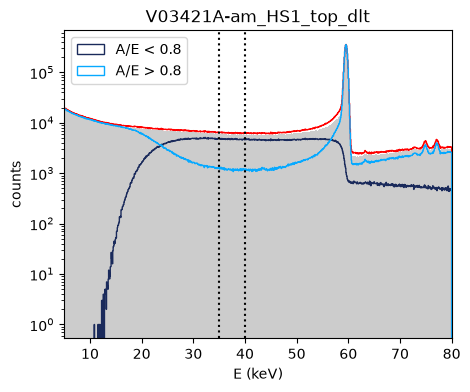

In [268]:
plt.figure(figsize = (5,4))
plt.hist(ene, bins = 1000, color  = grigio, range = (0, 80))
plt.hist(ene_raw, bins = 1000, color  = 'red', histtype = 'step',  range = (0, 80))
plt.hist(ene[aoe_norm<cut], bins = 1000, color = blue, histtype = 'step', range = (0, 80), label = f'A/E < {cut}')
plt.hist(ene[aoe_norm>cut], bins = 1000, color = azzurro, histtype = 'step',range = (0, 80), label = f'A/E > {cut}')
plt.legend()
plt.yscale('log')
plt.xlabel('E (keV)')
plt.ylabel('counts')
#plt.axvline(30, color = 'grey', ls = '--')
#plt.axvline(45, color = 'grey', ls = '--')
plt.axvline(35, color = 'black', ls = ':')
plt.axvline(40, color = 'black', ls = ':')
plt.title(f'{detector}-{measure}')
plt.xlim(5,80)

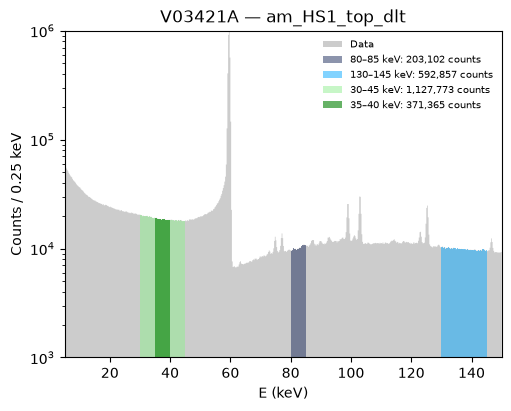

In [269]:
fig, ax = plt.subplots(
    figsize=(5, 4),
    #dpi=200,
    layout="constrained",
)

# Istogramma calcolato una sola volta.
c, be = np.histogram(
    ene,
    bins=600,
    range=(0, 150),
)

bc = (be[:-1] + be[1:]) / 2

ax.stairs(
    c,
    be,
    color=grigio,
    linewidth=0.8,
    
        fill=True,
    label="Data",
)

# Finestre selezionate usando i centri dei bin.
windows = [
    (80, 85, blue, 0.5),
    (130, 145, azzurro, 0.5),
    (30, 45, "lightgreen", 0.5),
    (35, 40, "green", 0.6),
]

for low, high, color, alpha in windows:
    mask = (bc >= low) & (bc < high)
    indices = np.flatnonzero(mask)

    if not indices.size:
        continue

    first = indices[0]
    last = indices[-1] + 1

    ax.stairs(
        c[first:last],
        be[first:last + 1],
        baseline=0,
        fill=True,
        color=color,
        alpha=alpha,
        label=f"{low}–{high} keV: {c[mask].sum():,.0f} counts",
    )

ax.set_yscale("log")
ax.set_xlim(5, 150)
ax.set_ylim(1e3, 1e6)

ax.set_xlabel("E (keV)")
ax.set_ylabel(f"Counts / {be[1] - be[0]:.2f} keV")
ax.set_title(f"{detector} — {measure}")

ax.legend(
    frameon=False,
    fontsize=7,
)

plt.show()

In [270]:
bc = (bins[1:]+bins[:-1]) * 0.5

In [271]:
SP_net = np.sum(counts_clean[(bc>30)&(bc<45)] - counts_clean[(bc>130)&(bc<145)])
p60_net = counts_net

In [272]:
Odlf = SP_net/p60_net

print(f'ratio for DLF = {Odlf}')

ratio for DLF = 0.17714389327905644


# DLF counting method

# Sims

In [273]:
import awkward as ak

In [274]:
detectors = [
    "V03421A",
    "V03422A",
    "V06643A",
    "V06659A",
    "V07298B",
    "V07302A",
    "V07302B",
    "V07647B",
    "V10437B",
    "V10447B",
    "V10784A",
    "V11924A",
    "V11925A",
    "V11947B",
    "V13044A",
    "V13049A",
    "V14618A",
    "V14654A",
    "V14673A",
]
from pathlib import Path

root = Path("/global/u2/r/ritaferi/HADES_DATA/hades-metadata")
folder = root / "hardware" / "cryostat"

missing_detectors = [
    det
    for det in detectors
    if not any(
        (folder / f"{det}{extension}").is_file()
        for extension in (".yaml", ".yml", ".json")
    )
]

print("Detector con metadati del criostato mancanti:")
print(missing_detectors)
        

Detector con metadati del criostato mancanti:
['V10784A', 'V13044A', 'V13049A', 'V14618A', 'V14654A']


In [275]:
configuration = db.hardware.configuration[detector]["c1"][measure]

In [276]:
import os

In [277]:
output_dir = "/global/u2/r/ritaferi/HADES_DATA"

In [278]:
run_key

'run0003'

In [279]:
from pathlib import Path

roots = [
    Path("/tmp/hades-metadata-ritaferi"),
    Path("/global/u2/r/ritaferi/HADES_DATA/hades-metadata"),
]

for root in roots:
    folder = root / "hardware" / "cryostat"
    print(detector)

    matches = [
        folder / f"{detector}{extension}"
        for extension in (".yaml", ".yml", ".json")
        if (folder / f"{detector}{extension}").is_file()
    ]

    print(f"\n{root}")
    print(
        "\n".join(str(path) for path in matches)
        if matches
        else "Cryostat metadata missing."
    )

V03421A

/tmp/hades-metadata-ritaferi
Cryostat metadata missing.
V03421A

/global/u2/r/ritaferi/HADES_DATA/hades-metadata
/global/u2/r/ritaferi/HADES_DATA/hades-metadata/hardware/cryostat/V03421A.yaml


In [280]:
#run = "run0001"
config_geom = deepcopy(configuration[run_key])

gdml_file = os.path.join(
    output_dir, f"{detector}_{measure}_{run_key}.gdml"
)

if os.path.isfile(gdml_file):
    reg = gdml.Reader(gdml_file).getRegistry()
    print(f"GDML già presente, caricato: {gdml_file}")
else:
    reg = pygeomhades.core.construct(config_geom)
    os.makedirs(output_dir, exist_ok=True)
    write_pygeom(reg, gdml_file)
    print(f"GDML creato: {gdml_file}")

GDML già presente, caricato: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003.gdml


In [281]:

def collect_global_placements(logical_volume, parent_matrix=None):
    """
    Percorre ricorsivamente il GDML e restituisce la trasformazione
    globale di ogni volume fisico.
    """
    if parent_matrix is None:
        parent_matrix = np.eye(4)

    placements = {}

    def walk(mother_lv, mother_matrix):
        for pv in mother_lv.daughterVolumes:
            local_matrix = physical_volume_matrix(pv)
            global_matrix = mother_matrix @ local_matrix

            logical_name = pv.logicalVolume.name

            placements.setdefault(logical_name, []).append({
                "physical_name": pv.name,
                "logical_volume": pv.logicalVolume,
                "matrix": global_matrix,
            })

            walk(pv.logicalVolume, global_matrix)

    walk(logical_volume, parent_matrix)

    return placements


def find_germanium_detector(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Germanium" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessun detector al germanio trovato")

    if len(candidates) > 1:
        print("Detector al germanio trovati:", candidates)

    return candidates[0]



def find_source(reg):
    candidates = []

    for name, lv in reg.logicalVolumeDict.items():
        material_name = getattr(lv.material, "name", str(lv.material))

        if "Source" in material_name:
            candidates.append(name)

    if len(candidates) == 0:
        raise ValueError("Nessuna sorgente trovate")

    if len(candidates) > 1:
        print("Sorgente trovata:", candidates)

    return candidates[0]

def tubs_profile(solid):
    """Profilo r-z di un cilindro Tubs."""

    rmin = float(solid.evaluateParameterWithUnits("pRMin"))
    rmax = float(solid.evaluateParameterWithUnits("pRMax"))
    dz = float(solid.evaluateParameterWithUnits("pDz"))

    # pDz è la lunghezza totale lungo z
    zmin = -dz / 2
    zmax = dz / 2

    r = np.array([
        rmin,
        rmax,
        rmax,
        rmin,
        rmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def box_profile(solid):
    """Profilo nel piano locale x-z di un Box."""

    size_x = float(solid.evaluateParameterWithUnits("pX"))
    size_z = float(solid.evaluateParameterWithUnits("pZ"))

    xmin = -size_x / 2
    xmax = size_x / 2
    zmin = -size_z / 2
    zmax = size_z / 2

    r = np.array([
        xmin,
        xmax,
        xmax,
        xmin,
        xmin
    ])

    z = np.array([
        zmin,
        zmin,
        zmax,
        zmax,
        zmin
    ])

    return r, z

def transform_profile(r, z, matrix):
    """
    Trasforma un profilo locale (r, z) nelle coordinate globali.

    Parameters
    ----------
    r : array-like
        Coordinate radiali locali.
    z : array-like
        Coordinate verticali locali.
    matrix : array-like, shape (4, 4)
        Matrice omogenea contenente rotazione e traslazione globali.

    Returns
    -------
    radius : ndarray
        Distanza globale dall'asse z.
    height : ndarray
        Coordinata z globale.
    """

    r = np.asarray(r, dtype=float)
    z = np.asarray(z, dtype=float)

    # Punti omogenei locali: (x=r, y=0, z, 1)
    points = np.column_stack([
        r,
        np.zeros_like(r),
        z,
        np.ones_like(r)
    ])

    # Trasformazione nelle coordinate globali
    transformed = (matrix @ points.T).T

    x_global = transformed[:, 0]
    y_global = transformed[:, 1]
    z_global = transformed[:, 2]

    radius = np.sqrt(x_global**2 + y_global**2)
    height = z_global
    
    return radius, height

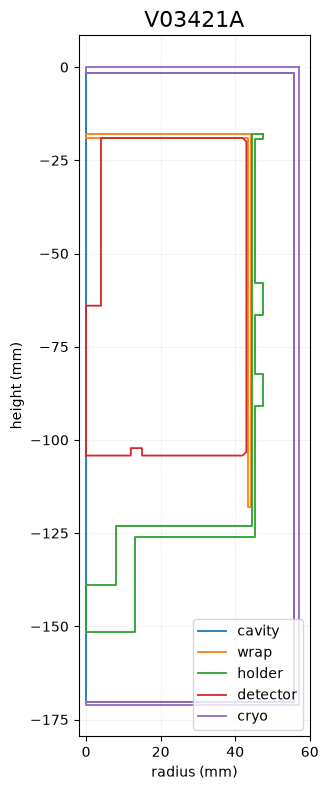

In [282]:
def generic_polycone_profile(solid):
    r = np.asarray(
        solid.evaluateParameterWithUnits("pR"),
        dtype=float
    )
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZ"),
        dtype=float
    )

    return np.append(r, r[0]), np.append(z, z[0])


def polycone_profile(solid):
    z = np.asarray(
        solid.evaluateParameterWithUnits("pZpl"),
        dtype=float
    )
    rmin = np.asarray(
        solid.evaluateParameterWithUnits("pRMin"),
        dtype=float
    )
    rmax = np.asarray(
        solid.evaluateParameterWithUnits("pRMax"),
        dtype=float
    )

    r = np.concatenate([rmax, rmin[::-1], [rmax[0]]])
    z = np.concatenate([z, z[::-1], [z[0]]])

    return r, z

    
def get_profile(solid):
    solid_type = str(solid.type).lower()

    if "genericpolycone" in solid_type:
        return generic_polycone_profile(solid)

    if "polycone" in solid_type:
        return polycone_profile(solid)

    if "tubs" in solid_type or "tube" in solid_type:
        return tubs_profile(solid)

    if "box" in solid_type:
        return box_profile(solid)

    raise TypeError(
        f"Solido {solid.name} di tipo {solid.type} non supportato"
    )

def evaluate_vector(vector):
    """Converte Position o Rotation di pyg4ometry in array numerico."""
    return np.asarray(vector.eval(), dtype=float)


def physical_volume_matrix(pv):
    """Matrice omogenea della trasformazione del PhysicalVolume."""
    position = evaluate_vector(pv.position)
    rotation = evaluate_vector(pv.rotation)

    rotation_matrix = np.linalg.inv(
        pg4.transformation.tbxyz2matrix(rotation)
    )

    matrix = np.eye(4)
    matrix[:3, :3] = rotation_matrix
    matrix[:3, 3] = position

    return matrix

placements = collect_global_placements(reg.getWorldVolume())

detector_name = find_germanium_detector(reg)

components = {
    "cavity_lv": {
        "label": "cavity",
        "color": "tab:blue"
    },
    "Wrap": {
        "label": "wrap",
        "color": "tab:orange"
    },
    "Holder": {
        "label": "holder",
        "color": "tab:green"
    },
    detector_name: {
        "label": "detector",
        "color": "tab:red"
    },
    "Cryostat": {
        "label": "cryo",
        "color": "tab:purple"
    },
}

fig, ax = plt.subplots(figsize=(4,8))

for logical_name, style in components.items():

    if logical_name not in placements:
        print(f"Volume non trovato: {logical_name}")
        continue

    # Se esistono più copie, le disegna tutte
    for index, placement in enumerate(placements[logical_name]):

        lv = placement["logical_volume"]
        matrix = placement["matrix"]

        try:
            r_local, z_local = get_profile(lv.solid)
        except TypeError as error:
            print(error)
            continue

        radius, height = transform_profile(
            r_local,
            z_local,
            matrix
        )

        # Una sola voce in legenda per componente
        label = style["label"] if index == 0 else None

        ax.plot(
            radius,
            height,
            color=style["color"],
            linewidth=1.3,
            label=label
        )

ax.set_title(detector_name, fontsize=16)
ax.set_xlabel("radius (mm)")
ax.set_ylabel("height (mm)")

ax.set_xlim(left=-2)
ax.set_aspect("equal", adjustable="box")

ax.grid(alpha=0.15)
ax.legend(loc = 'lower right')

plt.tight_layout()
plt.show()

In [283]:
import os

In [284]:
run_key

'run0003'

In [342]:
peaks = {
    #"gamma_59p9keV": 59.5,
    #"gamma_99keV": 99.0,
    #"gamma_103keV": 103.0,
    #"gamma_123p1keV": 123.1,
    #"gamma_125p3keV": 125.3,
    #"gamma_208p1keV": 208.1,
    #"gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
}

N_sim = 10000000


force_rerun = False

os.makedirs(output_dir, exist_ok=True)
simulation_files = {}

for name, energy_keV in peaks.items():

    output_file = os.path.join(
        output_dir,
        f"{detector}_{measure}_{run_key}_{name}.lh5"
    )

    if os.path.isfile(output_file) and not force_rerun:
        simulation_files[name] = output_file
        print(f"✅ {name}: uso il file esistente → {output_file}")
        continue

    macro = [
        "/RMG/Manager/Logging/LogLevel summary",
        "/RMG/Processes/HadronicPhysics Shielding",
    
        f"/RMG/Geometry/RegisterDetector Germanium {detector} 1",
    
        "/RMG/Output/NtupleUseVolumeName true",
        "/RMG/Output/NtuplePerDetector false",
    
        "/run/initialize",
    
        "/RMG/Generator/Confine Volume",
        "/RMG/Generator/Confinement/Physical/AddVolume Source_PV",
    
        "/RMG/Generator/Select GPS",
        "/gps/particle gamma",
        "/gps/number 1",
        "/gps/ene/type Mono",
        f"/gps/ene/mono {energy_keV} keV",
        "/gps/ang/type iso",
    
        f"/run/beamOn {int(N_sim)}",
    ]
    print(f"▶ {name}: avvio simulazione → {output_file}")

    try:
        remage_run(
            macros=macro,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True,
        )
        simulation_files[name] = output_file
        print(f"✅ {name}: simulazione completata")

    except Exception as e:
        print(f"❌ {name}: {e}")

print("\nFile disponibili:", simulation_files)



✅ gamma_662p4keV: uso il file esistente → /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_662p4keV.lh5

File disponibili: {'gamma_662p4keV': '/global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_662p4keV.lh5'}


In [343]:


N_sim_by_peak = {}
energies = ["gamma_59p9keV", "gamma_99keV","gamma_103keV",
    "gamma_123p1keV",
    "gamma_125p3keV",
    "gamma_208p1keV",
    "gamma_335p4keV",
    "gamma_662p4keV"]

for name in energies:
    filename = os.path.join(
        output_dir, f"{detector}_{measure}_{run_key}_{name}.lh5"
    )

    obj = lh5.read("number_of_simulated_events", filename)

    # Compatibilità con versioni che restituiscono una tupla
    if isinstance(obj, tuple):
        obj = obj[0]

    N_sim_by_peak[name] = int(obj.value)
    print(f"{name}: {N_sim_by_peak[name]:,} eventi simulati")

gamma_59p9keV: 100,000,000 eventi simulati
gamma_99keV: 10,000,000 eventi simulati
gamma_103keV: 10,000,000 eventi simulati
gamma_123p1keV: 10,000,000 eventi simulati
gamma_125p3keV: 10,000,000 eventi simulati
gamma_208p1keV: 10,000,000 eventi simulati
gamma_335p4keV: 10,000,000 eventi simulati
gamma_662p4keV: 10,000,000 eventi simulati


In [532]:
#data = lh5.read_as("stp/germanium", filename, "ak", with_units = True)

In [538]:
print("xloc:", obj.attrs)

if hasattr(obj, "flattened_data"):
    print("Dati interni:", obj.flattened_data.attrs)

table = lh5.read("stp/germanium", filename)

if isinstance(table, tuple):
    table = table[0]

print("Tabella:", table.attrs)

xloc: {'datatype': 'array<1>{array<1>{real}}'}
Dati interni: {'datatype': 'array<1>{real}', 'units': 'm'}
Tabella: {'datatype': 'table{det_uid,dist_to_surf,edep,evtid,particle,t0,time,xloc,yloc,zloc}'}


In [345]:
print("Campi disponibili:")
print(ak.fields(data))

Campi disponibili:
['det_uid', 'dist_to_surf', 'edep', 'evtid', 'particle', 't0', 'time', 'xloc', 'yloc', 'zloc']


In [346]:
ak.fields(data[0])

['det_uid',
 'dist_to_surf',
 'edep',
 'evtid',
 'particle',
 't0',
 'time',
 'xloc',
 'yloc',
 'zloc']

In [509]:
data[1]['xloc']

<Array [-0.00469, -0.00469, -0.00237, 0.00326] type='4 * float64'>

In [545]:
for pv_name in (
    "source_pv_1",
    "Collimator_Beam_PV",
    "Source_Encapsulated_PV",
    "Source_PV",
):
    pv = reg.physicalVolumeDict.get(pv_name)

    if pv is None:
        continue

    lv = pv.logicalVolume
    material = lv.material

    print(
        f"{pv_name}\n"
        f"  Volume: {lv.name}\n"
        f"  Materiale: {getattr(material, 'name', material)}\n"
        f"  Densità: {getattr(material, 'density', 'non disponibile')}\n"
    )

source_pv_1
  Volume: Source_Collimated
  Materiale: G4_Cu
  Densità: None

Collimator_Beam_PV
  Volume: Collimator_Beam
  Materiale: Air
  Densità: 0.00120479

Source_Encapsulated_PV
  Volume: Source_Encapsulated
  Materiale: Ssteel
  Densità: 7.9

Source_PV
  Volume: Source
  Materiale: SiliconDioxide
  Densità: 2.32



In [546]:
print("File analizzato:", filename)

File analizzato: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_662p4keV.lh5


GDML letto: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003.gdml
wrap_pv_1: origine world = [ -0.   0. -18.] mm
holder_pv_1: origine world = [ -0.   0. -18.] mm
V03421A: origine world = [  -0.     0.  -104.2] mm
cryo_pv_1: origine world = [0. 0. 0.] mm
source_pv_1: origine world = [-22.    0.   37.5] mm
Collimator_Beam_PV: origine world = [-22.    0.   17.8] mm
Source_Encapsulated_PV: origine world = [-22.    0.   35.6] mm
Source_PV: origine world = [-22.    0.   31.8] mm


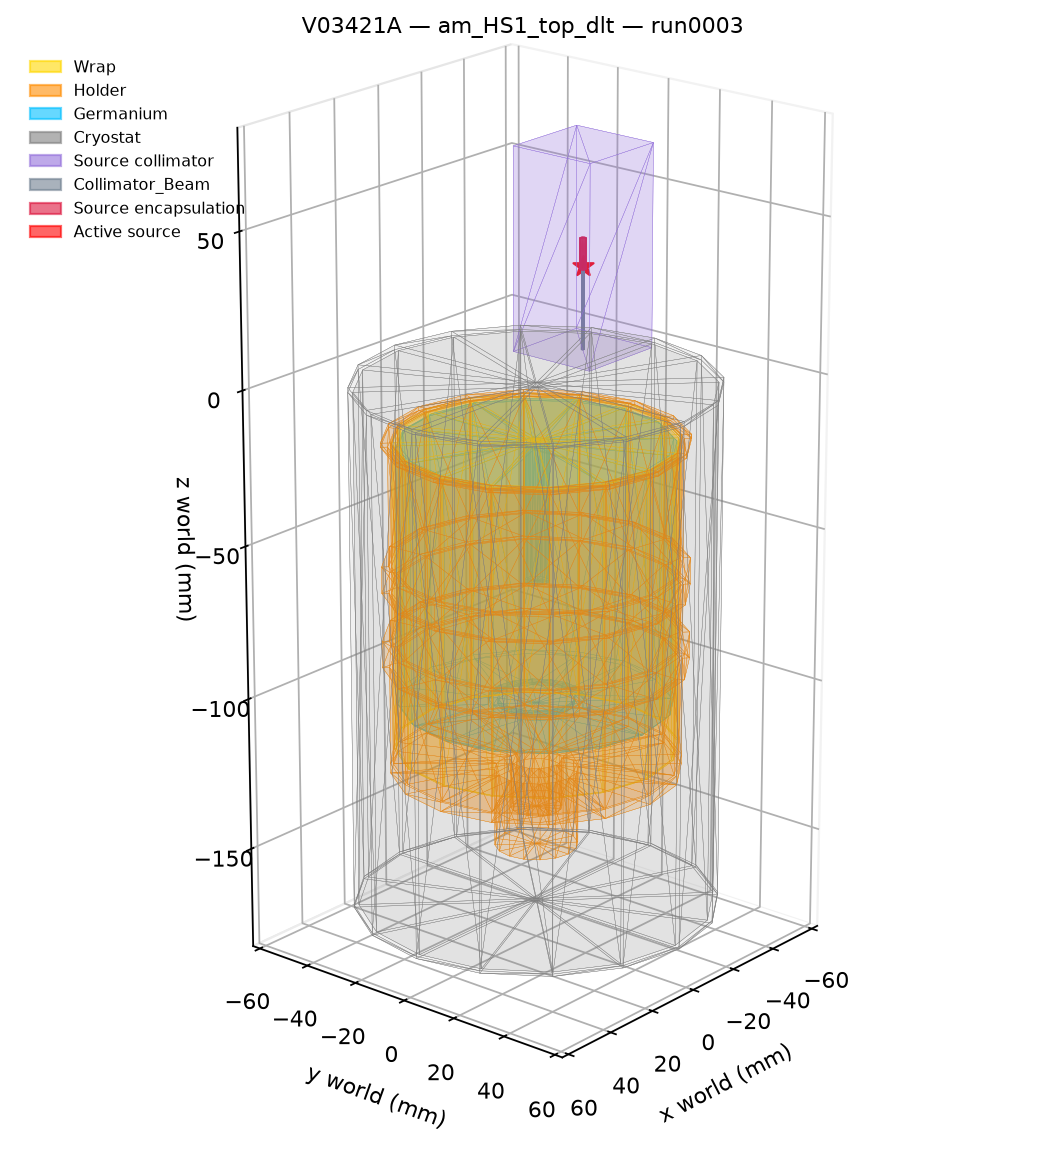

In [504]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from pyg4ometry import gdml
from pyg4ometry.transformation import tbxyz2matrix
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Patch


def plot_geometry_from_gdml(
    gdml_file,
    detector,
    measure="",
    run_key="",
    figsize=(8, 7),
    elev=20,
    azim=40,
):
    # ========================================================
    # READ THE GDML AGAIN
    # ========================================================

    path = Path(gdml_file).expanduser().resolve()

    if not path.is_file():
        raise FileNotFoundError(f"GDML non trovato: {path}")

    registry = gdml.Reader(str(path)).getRegistry()
    world = registry.getWorldVolume()

    print(f"GDML letto: {path}")

    # ========================================================
    # STYLES
    # ========================================================

    def style_for(pv):
        name = pv.logicalVolume.name.lower()

        if (
            pv.name == detector
            or pv.logicalVolume.name == detector
        ):
            return "deepskyblue", 0.25, "Germanium"

        if "wrap" in name:
            return "gold", 0.12, "Wrap"

        if "holder" in name:
            return "darkorange", 0.12, "Holder"

        if "cryostat" in name:
            return "gray", 0.06, "Cryostat"

        if name == "source":
            return "red", 0.8, "Active source"

        if "encapsulated" in name:
            return "crimson", 0.25, "Source encapsulation"

        if "source_collimated" in name:
            return "mediumpurple", 0.15, "Source collimator"

        # Mostra anche componenti aggiuntivi,
        # escludendo soltanto i contenitori di ambiente.
        if name in ("world_lv", "lab_lv", "cavity_lv"):
            return None

        return "slategray", 0.10, pv.logicalVolume.name

    def vector(value, default):
        if value is None:
            return np.asarray(default, dtype=float)

        if hasattr(value, "eval"):
            value = value.eval()

        return np.asarray(value, dtype=float)

    # ========================================================
    # TRANSFORMATIONS FROM GDML
    # ========================================================

    placements = []

    def traverse(lv, parent_matrix, parent_position, parent_path):
        for pv in getattr(lv, "daughterVolumes", []):
            angles = vector(
                getattr(pv, "rotation", None),
                [0, 0, 0],
            )

            position = vector(
                getattr(pv, "position", None),
                [0, 0, 0],
            )

            scale = vector(
                getattr(pv, "scale", None),
                [1, 1, 1],
            )

            rotation = np.linalg.inv(
                np.asarray(tbxyz2matrix(angles), dtype=float)
            )

            # Include any scale explicitly stored in the GDML.
            local_matrix = rotation @ np.diag(scale)

            matrix_world = parent_matrix @ local_matrix
            position_world = (
                parent_matrix @ position
                + parent_position
            )

            current_path = f"{parent_path}/{pv.name}"

            placements.append({
                "pv": pv,
                "matrix": matrix_world,
                "position": position_world,
                "path": current_path,
            })

            traverse(
                pv.logicalVolume,
                matrix_world,
                position_world,
                current_path,
            )

    traverse(
        world,
        np.eye(3),
        np.zeros(3),
        world.name,
    )

    if not any(
        item["pv"].name == detector
        or item["pv"].logicalVolume.name == detector
        for item in placements
    ):
        raise ValueError(
            f"{detector} non presente in {path.name}."
        )

    # ========================================================
    # DRAW GEOMETRY
    # ========================================================

    fig = plt.figure(
        figsize=figsize,
        dpi=160,
        layout="constrained",
        facecolor="white",
    )

    ax = fig.add_subplot(111, projection="3d")
    ax.set_facecolor("white")

    all_vertices = []
    handles = {}
    transforms = {}

    for item in placements:
        pv = item["pv"]

        # Conserva anche le trasformazioni dei contenitori.
        transforms[item["path"]] = {
            "matrix": item["matrix"].copy(),
            "translation_mm": item["position"].copy(),
        }

        style = style_for(pv)

        if style is None:
            continue

        color, alpha, label = style

        mesh_data = (
            pv.logicalVolume.mesh
            .getLocalMesh()
            .toVerticesAndPolygons()
        )

        vertices = (
            np.asarray(mesh_data[0], dtype=float)
            @ item["matrix"].T
            + item["position"]
        )

        faces = [
            vertices[np.asarray(face, dtype=int)]
            for face in mesh_data[1]
            if len(face) >= 3
        ]

        if not faces:
            continue

        ax.add_collection3d(
            Poly3DCollection(
                faces,
                facecolor=color,
                edgecolor=color,
                linewidths=0.15,
                alpha=alpha,
            )
        )

        all_vertices.append(vertices)

        if label not in handles:
            handles[label] = Patch(
                facecolor=color,
                edgecolor=color,
                alpha=0.6,
                label=label,
            )

        if label == "Active source":
            ax.scatter(
                *item["position"],
                color="red",
                marker="*",
                s=90,
                depthshade=False,
            )

        print(
            f"{pv.name}: "
            f"origine world = "
            f"{np.round(item['position'], 3)} mm"
        )

    if not all_vertices:
        plt.close(fig)
        raise ValueError("Nessuna mesh da mostrare.")

    vertices = np.concatenate(all_vertices)

    lower = vertices.min(axis=0)
    upper = vertices.max(axis=0)

    extent = np.maximum(upper - lower, 1.0)
    padding = 0.05 * extent

    ax.set_xlim(lower[0] - padding[0], upper[0] + padding[0])
    ax.set_ylim(lower[1] - padding[1], upper[1] + padding[1])
    ax.set_zlim(lower[2] - padding[2], upper[2] + padding[2])

    ax.set_box_aspect(extent + 2 * padding)
    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel("x world (mm)")
    ax.set_ylabel("y world (mm)")
    ax.set_zlabel("z world (mm)")

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_facecolor("white")
        axis.pane.set_alpha(1.0)

    ax.set_title(
        " — ".join(
            str(value)
            for value in (detector, measure, run_key)
            if value
        ),
        fontsize=10,
    )

    ax.legend(
        handles=list(handles.values()),
        loc="upper left",
        fontsize=7,
        frameon=False,
    )

    plt.show()

    return registry, fig, ax, transforms


# ============================================================
# GDML OF THE CURRENT DETECTOR / MEASUREMENT / RUN
# ============================================================

gdml_file = (
    Path(output_dir)
    / f"{detector}_{measure}_{run_key}.gdml"
)

reg, fig, ax, geometry_transforms = plot_geometry_from_gdml(
    gdml_file,
    detector=detector,
    measure=measure,
    run_key=run_key,
)

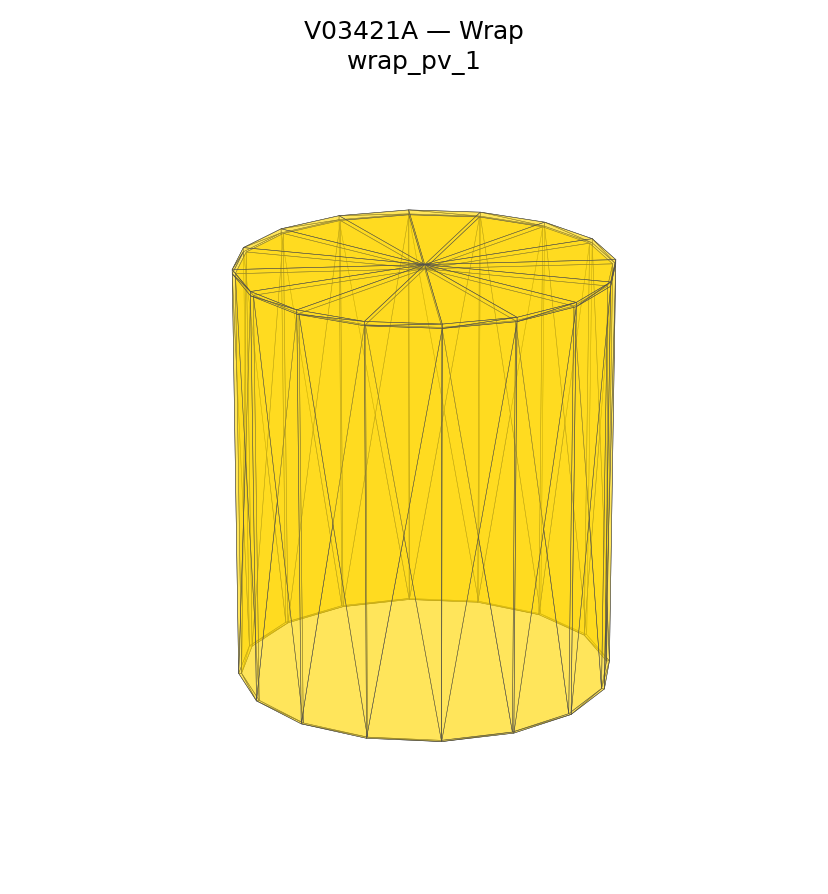

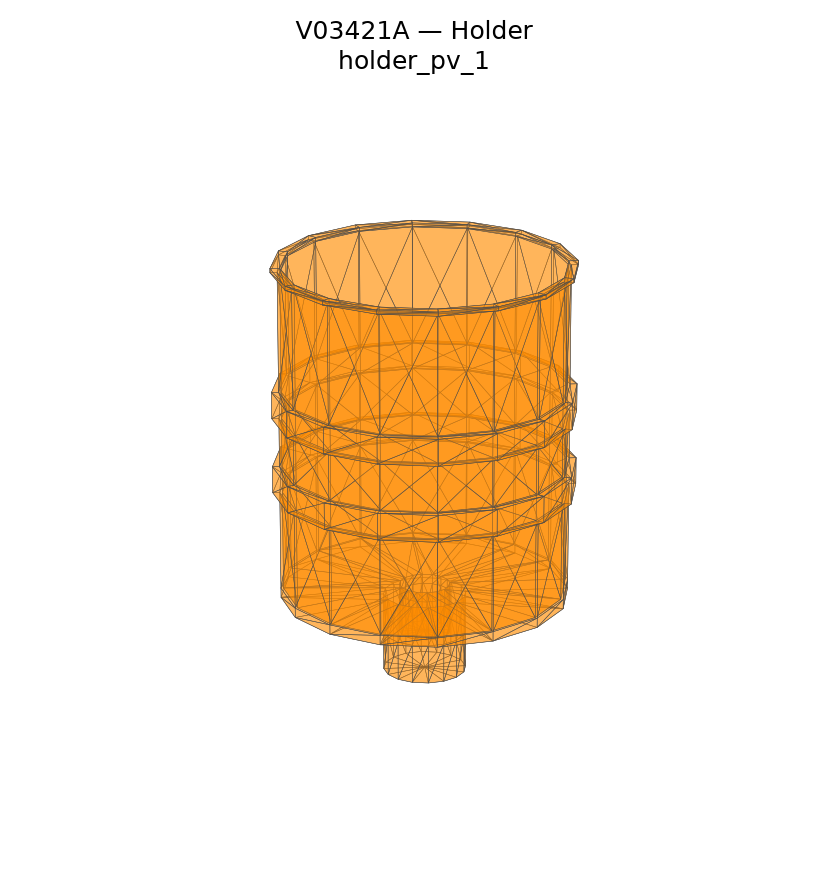

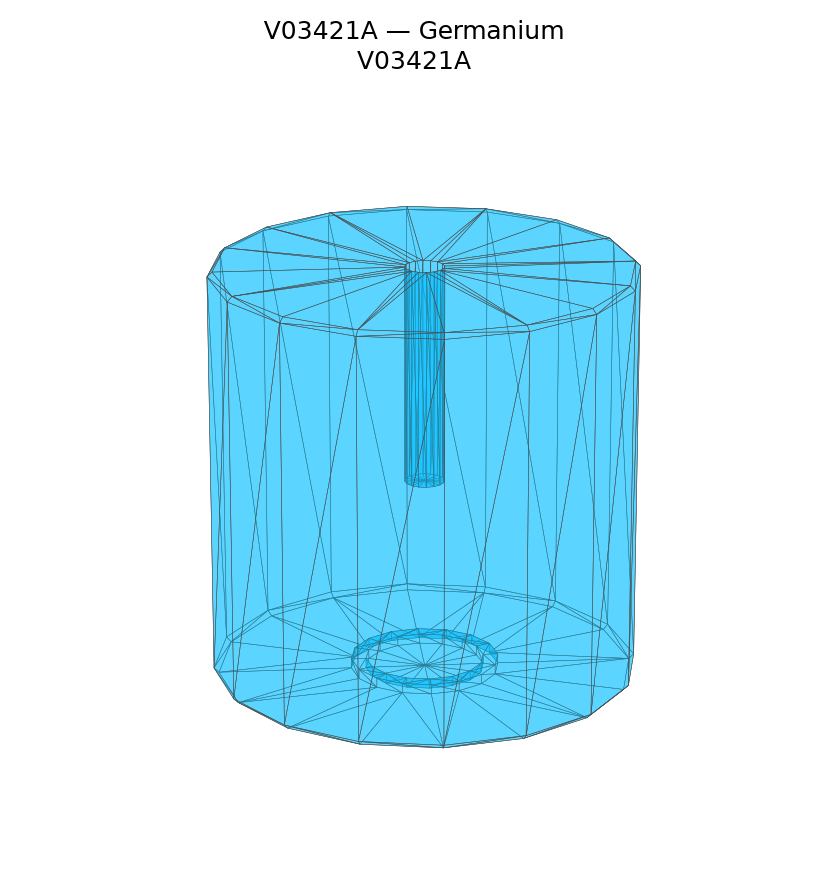

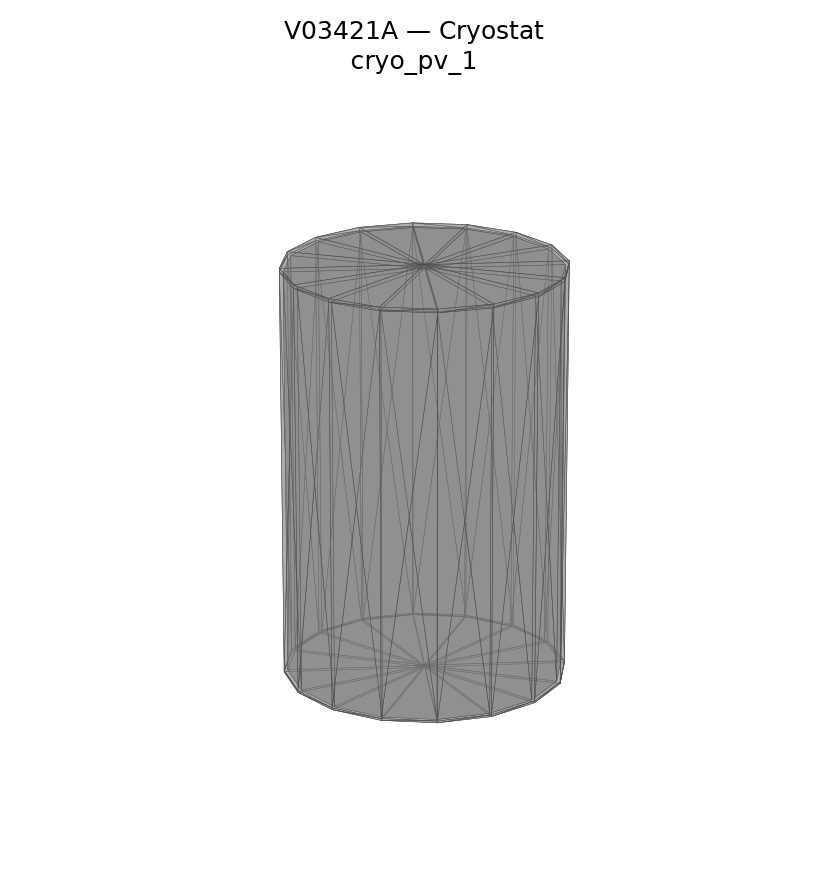

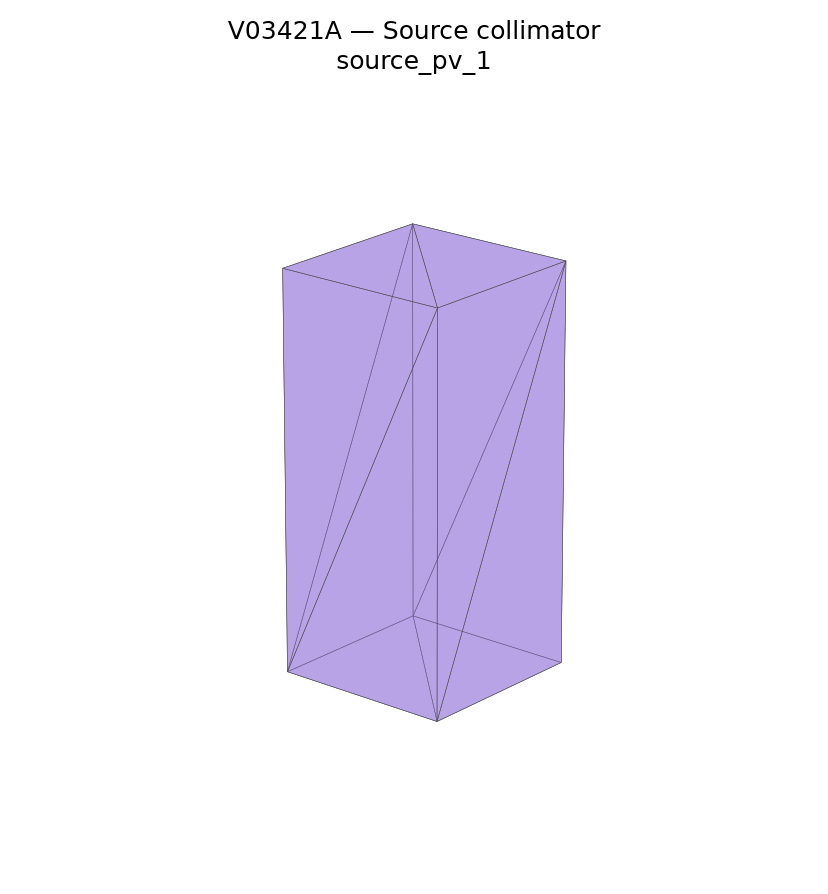

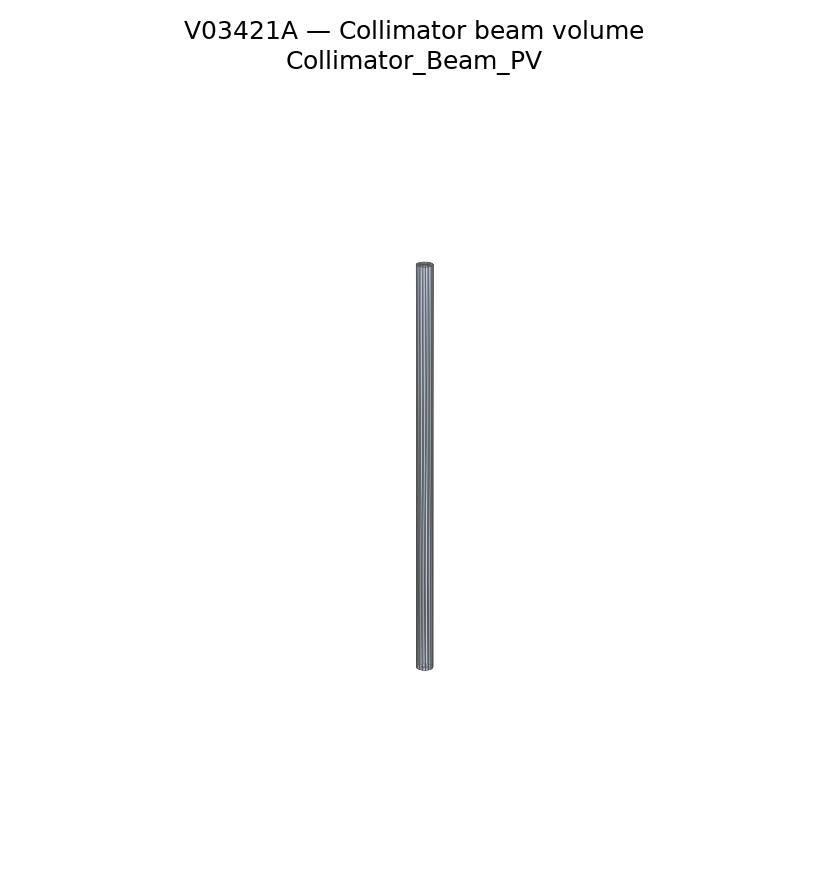

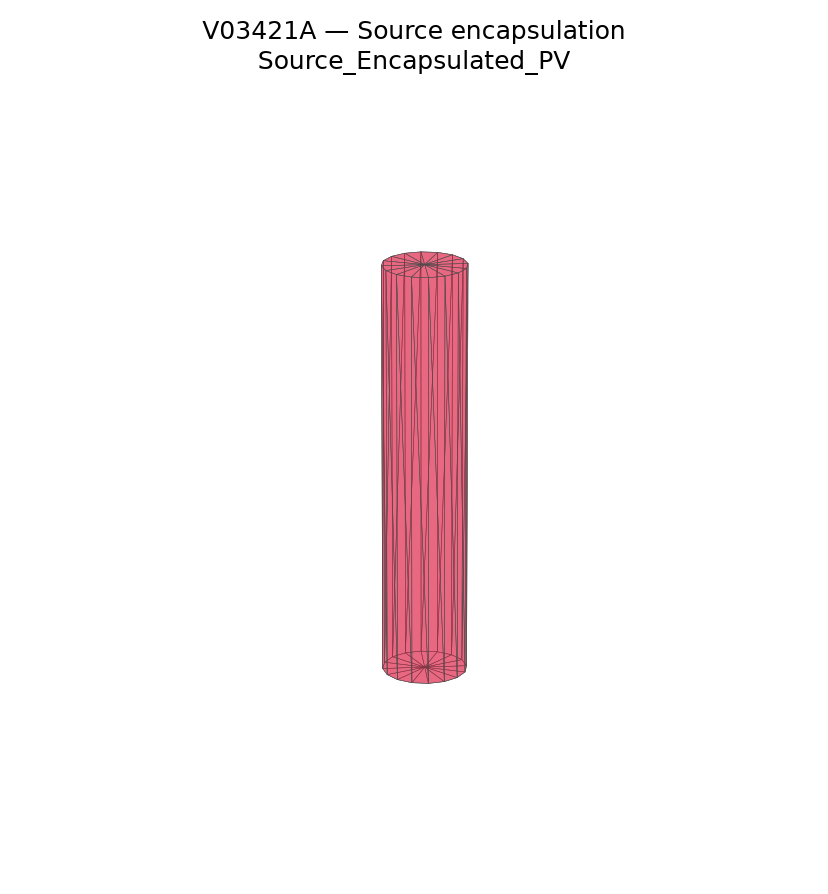

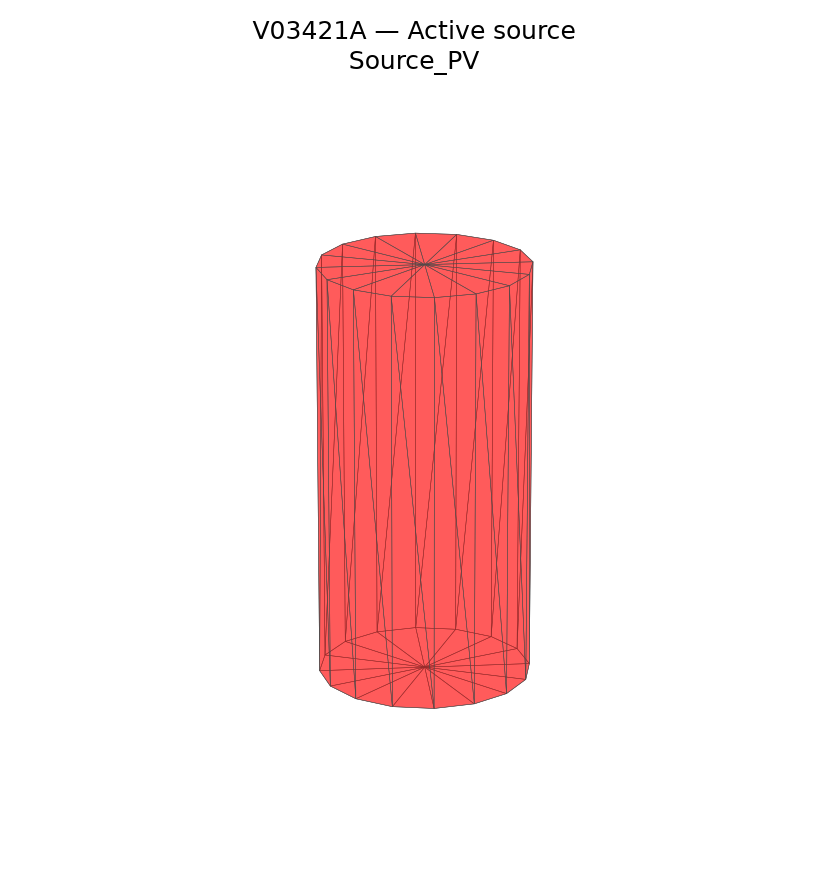

In [524]:


def plot_geometry_components(
    gdml_file,
    detector,
    figsize=(6, 5),
    elev=20,
    azim=40,
):
    path = Path(gdml_file).expanduser().resolve()

    if not path.is_file():
        raise FileNotFoundError(path)

    registry = gdml.Reader(str(path)).getRegistry()

    def evaluate(value, default):
        if value is None:
            return np.asarray(default, dtype=float)

        if hasattr(value, "eval"):
            value = value.eval()

        return np.asarray(value, dtype=float)

    def style(pv):
        name = pv.logicalVolume.name.lower()

        if pv.name == detector or pv.logicalVolume.name == detector:
            return "Germanium", "deepskyblue"

        if "wrap" in name:
            return "Wrap", "gold"

        if "holder" in name:
            return "Holder", "darkorange"

        if "cryostat" in name:
            return "Cryostat", "gray"

        if name == "source":
            return "Active source", "red"

        if "encapsulated" in name:
            return "Source encapsulation", "crimson"

        if "source_collimated" in name:
            return "Source collimator", "mediumpurple"

        if "collimator_beam" in name:
            return "Collimator beam volume", "lightsteelblue"

        # Non disegna i contenitori dell'ambiente.
        if name in ("world_lv", "lab_lv", "cavity_lv"):
            return None

        return pv.logicalVolume.name, "steelblue"

    figures = {}

    def traverse(lv, parent_matrix, parent_position, parent_path):
        for pv in getattr(lv, "daughterVolumes", []):
            angles = evaluate(
                getattr(pv, "rotation", None),
                [0, 0, 0],
            )

            position = evaluate(
                getattr(pv, "position", None),
                [0, 0, 0],
            )

            scale = evaluate(
                getattr(pv, "scale", None),
                [1, 1, 1],
            )

            local_matrix = (
                np.linalg.inv(
                    np.asarray(tbxyz2matrix(angles), dtype=float)
                )
                @ np.diag(scale)
            )

            matrix = parent_matrix @ local_matrix
            translation = parent_matrix @ position + parent_position
            current_path = f"{parent_path}/{pv.name}"

            component_style = style(pv)

            if component_style is not None:
                label, color = component_style

                mesh = (
                    pv.logicalVolume.mesh
                    .getLocalMesh()
                    .toVerticesAndPolygons()
                )

                vertices = (
                    np.asarray(mesh[0], dtype=float) @ matrix.T
                    + translation
                )

                faces = [
                    vertices[np.asarray(face, dtype=int)]
                    for face in mesh[1]
                    if len(face) >= 3
                ]

                if faces:
                    fig = plt.figure(
                        figsize=figsize,
                        dpi=180,
                        facecolor="white",
                    )

                    ax = fig.add_subplot(111, projection="3d")
                    ax.set_facecolor("white")

                    ax.add_collection3d(
                        Poly3DCollection(
                            faces,
                            facecolor=color,
                            edgecolor="0.3",
                            linewidths=0.2,
                            alpha=0.4,
                        )
                    )

                    lower = vertices.min(axis=0)
                    upper = vertices.max(axis=0)
                    center = (lower + upper) / 2

                    half_span = max(
                        float(np.max(upper - lower)) * 0.55,
                        0.1,
                    )

                    ax.set_xlim(
                        center[0] - half_span,
                        center[0] + half_span,
                    )
                    ax.set_ylim(
                        center[1] - half_span,
                        center[1] + half_span,
                    )
                    ax.set_zlim(
                        center[2] - half_span,
                        center[2] + half_span,
                    )

                    ax.set_box_aspect((1, 1, 1))
                    ax.view_init(elev=elev, azim=azim)
                    ax.set_axis_off()

                    ax.set_title(
                        f"{detector} — {label}\n{pv.name}",
                        fontsize=10,
                    )

                    fig.subplots_adjust(
                        left=0,
                        right=1,
                        bottom=0,
                        top=0.88,
                    )

                    figures[current_path] = fig

                    plt.show()

            # Visita anche i volumi figli.
            traverse(
                pv.logicalVolume,
                matrix,
                translation,
                current_path,
            )

    world = registry.getWorldVolume()

    traverse(
        world,
        np.eye(3),
        np.zeros(3),
        world.name,
    )

    return registry, figures


# GDML del detector e del run correnti.
gdml_file = (
    Path(output_dir)
    / f"{detector}_{measure}_{run_key}.gdml"
)

reg, component_figures = plot_geometry_components(
    gdml_file,
    detector=detector,
)

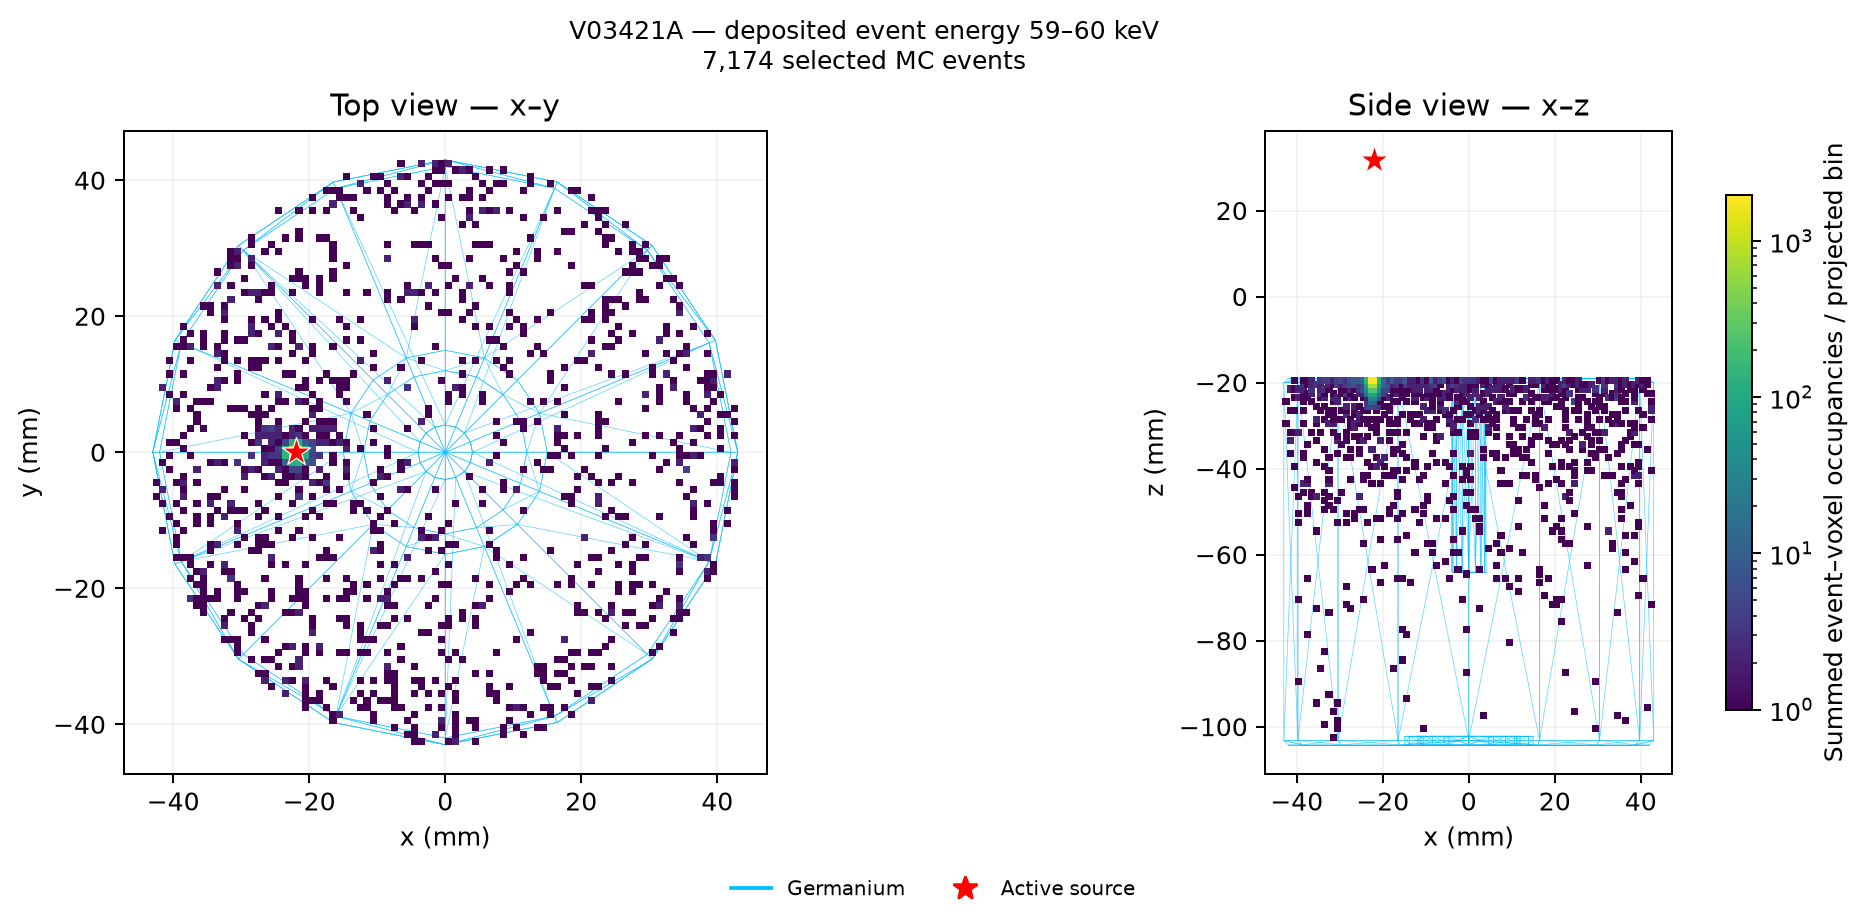

In [562]:
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

voxel_size_mm = 1
# ============================================================
# PROJECTED EVENT DENSITY
# Un evento può contribuire a più voxel nella stessa proiezione:
# qui sommiamo le occupazioni dei voxel lungo l'asse nascosto.
# ============================================================

def projected_density(axis1, axis2):
    projected_indices, inverse = np.unique(
        voxel_indices[:, [axis1, axis2]],
        axis=0,
        return_inverse=True,
    )

    projected_counts = np.zeros(
        len(projected_indices),
        dtype=np.int64,
    )

    np.add.at(
        projected_counts,
        inverse,
        counts,
    )

    projected_centers = (
        projected_indices + 0.5
    ) * voxel_size_mm

    return projected_centers, projected_counts


top_centers, top_counts = projected_density(0, 1)
side_centers, side_counts = projected_density(0, 2)

norm = LogNorm(
    vmin=1,
    vmax=max(
        2,
        int(top_counts.max()),
        int(side_counts.max()),
    ),
)


# ============================================================
# TOP AND SIDE VIEWS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5),
    dpi=180,
    layout="constrained",
    facecolor="white",
)

for ax, second_axis, projected_centers, projected_counts, title, ylabel in [
    (
        axes[0], 1,
        top_centers, top_counts,
        "Top view — x–y", "y (mm)",
    ),
    (
        axes[1], 2,
        side_centers, side_counts,
        "Side view — x–z", "z (mm)",
    ),
]:
    # Germanium mesh projected onto the selected plane.
    polygons = [
        face[:, [0, second_axis]]
        for face in detector_faces
    ]

    ax.add_collection(
        PolyCollection(
            polygons,
            facecolors="none",
            edgecolors="deepskyblue",
            linewidths=0.25,
            alpha=0.4,
            zorder=2,
        )
    )

    scatter = ax.scatter(
        projected_centers[:, 0],
        projected_centers[:, 1],
        c=projected_counts,
        cmap="viridis",
        norm=norm,
        marker="s",
        s=8,
        linewidths=0,
        rasterized=True,
        zorder=3,
    )

    ax.scatter(
        source_position[0],
        source_position[second_axis],
        marker="*",
        s=140,
        color="red",
        edgecolor="white",
        linewidth=0.5,
        zorder=5,
    )

    lower = np.minimum.reduce([
        detector_vertices[:, [0, second_axis]].min(axis=0),
        projected_centers.min(axis=0) - voxel_size_mm / 2,
        source_position[[0, second_axis]],
    ])

    upper = np.maximum.reduce([
        detector_vertices[:, [0, second_axis]].max(axis=0),
        projected_centers.max(axis=0) + voxel_size_mm / 2,
        source_position[[0, second_axis]],
    ])

    padding = np.maximum((upper - lower) * 0.05, 1.0)

    ax.set_xlim(lower[0] - padding[0], upper[0] + padding[0])
    ax.set_ylim(lower[1] - padding[1], upper[1] + padding[1])

    ax.set(
        xlabel="x (mm)",
        ylabel=ylabel,
        title=title,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_facecolor("white")
    ax.grid(alpha=0.15)

fig.colorbar(
    scatter,
    ax=axes,
    label="Summed event–voxel occupancies / projected bin",
    shrink=0.8,
    pad=0.03,
)

fig.legend(
    handles=[
        Line2D(
            [], [],
            color="deepskyblue",
            label="Germanium",
        ),
        Line2D(
            [], [],
            marker="*",
            color="red",
            linestyle="none",
            markersize=10,
            label="Active source",
        ),
    ],
    loc="outside lower center",
    ncol=2,
    frameon=False,
    fontsize=8,
)

fig.suptitle(
    f"{detector} — deposited event energy "
    f"{emin_keV:g}–{emax_keV:g} keV\n"
    f"{total_selected_events:,} selected MC events",
    fontsize=10,
)

plt.show()

In [487]:
peaks = {
    "gamma_59p9keV": 59.5,
    "gamma_99keV": 98.97,
    "gamma_103keV": 102.98,
    "gamma_123p1keV": 123.1,
    "gamma_125p3keV": 125.3,
    "gamma_208p1keV": 208.1,
    "gamma_335p4keV": 335.4,
    "gamma_662p4keV": 662.4,
}

In [361]:
import awkward as ak

PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_59p9keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_99keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_103keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_123p1keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_125p3keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_208p1keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_335p4keV.lh5 | esiste: True
PATH: /global/u2/r/ritaferi/HADES_DATA/V03421A_am_HS1_top_dlt_run0003_gamma_662p4keV.lh5 | esiste: True


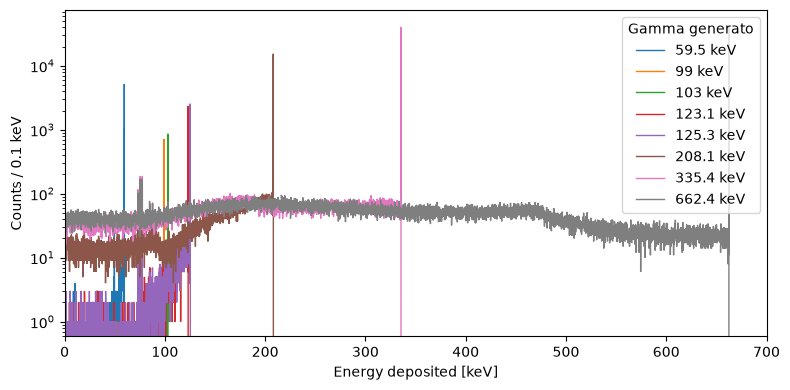

In [362]:
fig, ax = plt.subplots(figsize=(8, 4))
has_counts = False

for i, (name, energy_keV) in enumerate(peaks.items()):

    filename = simulation_files.get(
        name,
        os.path.join(
            output_dir,
            f"{detector}_{measure}_{run_key}_{name}.lh5"
        )
    )

    print("PATH:", filename, "| esiste:", os.path.isfile(filename))

    try:
        data = lh5.read_as("stp/germanium", filename, "ak")
        energy = ak.to_numpy(ak.sum(data.edep, axis=-1))
        energy = energy[energy > 0]

        counts, _ = np.histogram(energy, bins=bins)

        if counts.sum() == 0:
            print(f"{name}: nessun deposito nell'intervallo del grafico")
            continue

        ax.stairs(
            counts,
            bins,
            #color=colors[i % len(colors)],
            label=f"{energy_keV:g} keV"
        )
        has_counts = True

    except Exception:
        print(f"Errore durante la lettura o il grafico di {name}:")
        traceback.print_exc()

if has_counts:
    ax.set_xlabel("Energy deposited [keV]")
    ax.set_ylabel(f"Counts / {bins[1]-bins[0]:.1f} keV")
    ax.set_xlim(emin, 700)
    ax.set_yscale("log")
    ax.legend(title="Gamma generato")
    fig.tight_layout()
    plt.show()
else:
    plt.close(fig)
    print("Nessun conteggio da mostrare")

In [446]:
time_data




18000.0

In [439]:
# Probabilità di emissione per decadimento, NON percentuali.
BR = {
    "gamma_59p9keV":  0.3592,
    "gamma_99keV":    2.03e-4,
    "gamma_103keV":   1.95e-4,
    "gamma_123p1keV": 1.00e-5,
    "gamma_125p3keV": 4.08e-5,
    "gamma_208p1keV": 7.91e-6,
    "gamma_335p4keV": 4.96e-6,
    "gamma_662p4keV": 3.64e-6,
}


100000000
gamma_59p9keV: N_sim=100,000,000, peso=277.866
10000000
gamma_99keV: N_sim=10,000,000, peso=1.57122
10000000
gamma_103keV: N_sim=10,000,000, peso=1.5093
10000000
gamma_123p1keV: N_sim=10,000,000, peso=0.0774
10000000
gamma_125p3keV: N_sim=10,000,000, peso=0.315792
10000000
gamma_208p1keV: N_sim=10,000,000, peso=0.0612234
10000000
gamma_335p4keV: N_sim=10,000,000, peso=0.0383904
10000000
gamma_662p4keV: N_sim=10,000,000, peso=0.0281736


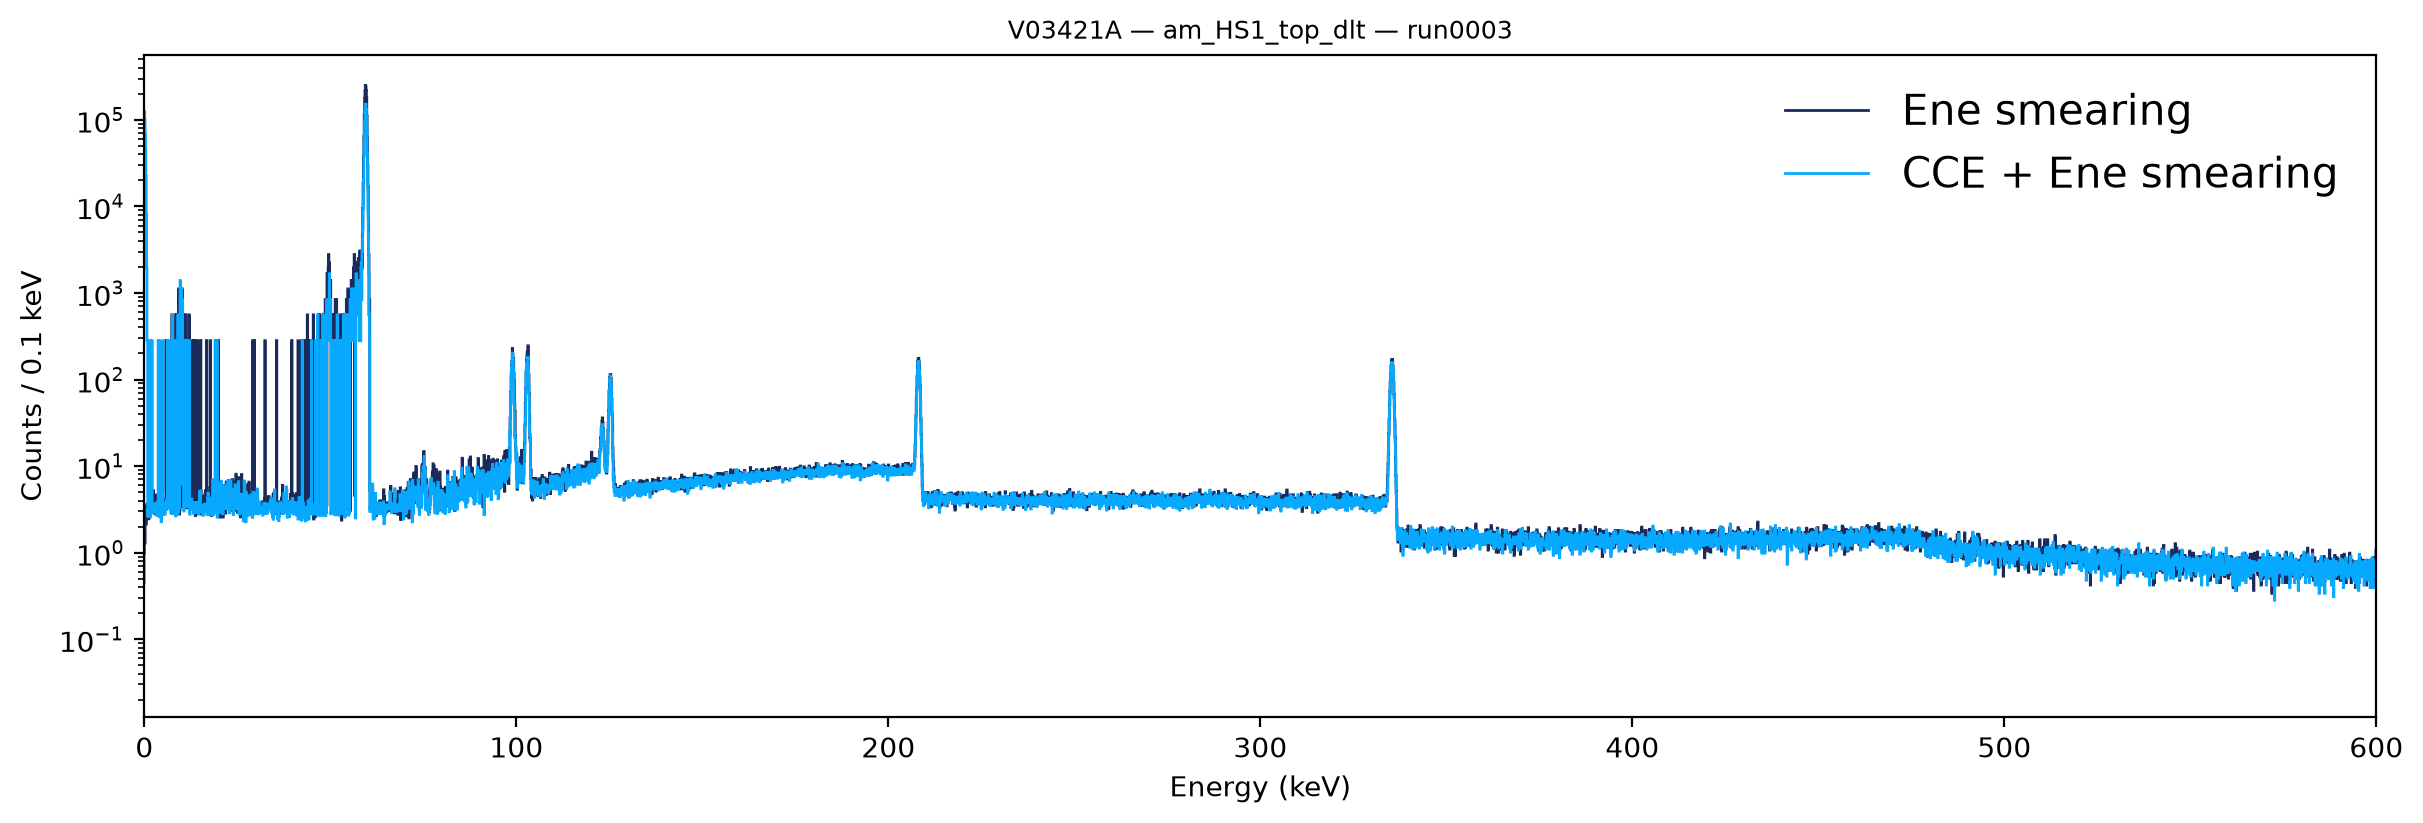

In [449]:

# ============================================================
# CONFIGURATION
# ============================================================

activity = 4.3e6  # Bq
fccd_mm = 0.5
dlf = 1
bins2= np.linspace(0, 700, 3500)
# 1. Solo risoluzione energetica.
counts_MC_teo = np.zeros(len(bins) - 1)
variance_MC_teo = np.zeros(len(bins) - 1)

# 2. CCE + risoluzione energetica.
counts_MC_cce = np.zeros(len(bins) - 1)
variance_MC_cce = np.zeros(len(bins) - 1)


# ============================================================
# LOOP OVER SIMULATED LINES
# ============================================================

for name, br in BR.items():

    filename = os.path.join(
        output_dir,
        f"{detector}_{measure}_{run_key}_{name}.lh5",
    )

    data = lh5.read_as(
        "stp/germanium",
        filename,
        "ak",
    )

    # Distanze di tutti gli step, già in mm.
    distance = data.dist_to_surf * 1000

    # --------------------------------------------------------
    # DEPOSITED ENERGY
    # --------------------------------------------------------

    energy_deposited = ak.to_numpy(
        ak.sum(data.edep, axis=-1)
    )

    # --------------------------------------------------------
    # APPLY CCE BEFORE SUMMING THE STEPS
    # --------------------------------------------------------

    activeness = functions.piecewise_linear_activeness(
        distance,
        fccd_in_mm=fccd_mm,
        dlf=dlf,
    )

    energy_collected = ak.to_numpy(
        ak.sum(data.edep * activeness, axis=-1)
    )

    # Stessa selezione per mantenere allineati gli eventi.
    selected = (
        np.isfinite(energy_deposited)
        & np.isfinite(energy_collected)
        & (energy_deposited > 0)
    )

    energy_deposited = energy_deposited[selected]
    energy_collected = energy_collected[selected]

    if energy_deposited.size == 0:
        print(f"{name}: nessun deposito positivo.")
        continue

    # --------------------------------------------------------
    # 1. FULL COLLECTION + ENERGY RESOLUTION
    # --------------------------------------------------------

    energy_theory_smeared = np.asarray(
        reboost.math.stats.gaussian_sample(
            energy_deposited,
            sigma=extract_sigma(energy_deposited),
        )
    )

    # --------------------------------------------------------
    # 2. CCE + ENERGY RESOLUTION
    # Sigma evaluated at the collected energy.
    # Events with no collected charge are excluded.
    # --------------------------------------------------------

    energy_cce_smeared = np.asarray(
            reboost.math.stats.gaussian_sample(
                energy_collected,
                sigma=extract_sigma(energy_collected),
            )
        )
    # --------------------------------------------------------
    # WEIGHT: ACTIVITY × TIME × BR / SIMULATED EVENTS
    # --------------------------------------------------------

    N_sim = N_sim_by_peak[name]

    if N_sim <= 0:
        raise ValueError(f"{name}: N_sim deve essere positivo.")

    print(N_sim)

    peso = activity * time_data * br / N_sim



    # Istogrammi non pesati, poi applicazione del peso.
    hist_teo, _ = np.histogram(
        energy_theory_smeared,
        bins=bins,
    )

    hist_cce, _ = np.histogram(
        energy_cce_smeared,
        bins=bins,
    )

    counts_MC_teo += hist_teo * peso
    counts_MC_cce += hist_cce * peso

    # Somma dei pesi al quadrato per bin.
    variance_MC_teo += hist_teo * peso**2
    variance_MC_cce += hist_cce * peso**2

    print(
        f"{name}: N_sim={N_sim:,}, "
        f"peso={peso:.6g}"
    )


# ============================================================
# TOTAL SPECTRA — NO FILE SAVING
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 4),
    dpi=200,
    layout="constrained",
)

ax.stairs(
    counts_MC_teo,
    bins,
    color=blue,
    #fill = True,
    label="Ene smearing",
)

ax.stairs(
    counts_MC_cce,
    bins,
    color=azzurro,
    label="CCE + Ene smearing",
)

ax.set_xlim(0, 600)
ax.set_yscale("log")
#ax.set_ylim(bottom=0.5)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1] - bins[0]:.1f} keV")
ax.set_title(f"{detector} — {measure} — {run_key}", fontsize=9)
ax.legend(frameon=False, fontsize=15)

plt.show()

In [442]:
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
)

for file in sorted(folder.glob("*/*_e_cal.npy")):
    print(file.parent.name, "→", file.name)

run0003 → V03421A_bkg_run0003_e_cal.npy


In [443]:
bkg_run = 'run0003'
folder = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
    / detector
    / bkg_run
)

energy_path = folder / f"{detector}_bkg_{bkg_run}_e_cal.npy"

if not energy_path.is_file():
    raise FileNotFoundError(
        f"Energie calibrate non trovate:\n{energy_path}\n"
        f"File disponibili: {[p.name for p in folder.glob('*')]}"
    )

# mmap evita di caricare subito tutto il file in memoria.
energy_bkg_cal = np.load(
    energy_path,
    mmap_mode="r",
    allow_pickle=False,
)

print(f"File: {energy_path}")
print(f"Eventi: {energy_bkg_cal.size:,}")

print(f"Detector: {detector} — {run_tag}")
print(f"Eventi: {energy_bkg_cal.size:,}")
#print("Prime energie (keV):", energy_bkg_cal[:10])

File: /global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/V03421A/run0003/V03421A_bkg_run0003_e_cal.npy
Eventi: 6,021,455
Detector: V03421A — r003
Eventi: 6,021,455


In [444]:
counts_bkg, _ = np.histogram(energy_bkg_cal, bins, weights = np.full(len(energy_bkg_cal),time_data / time_bkg))

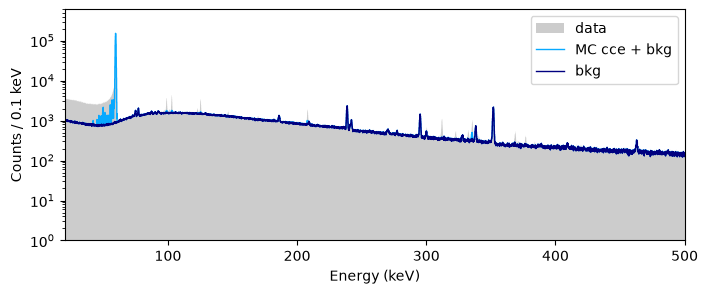

In [445]:
#plt.stairs(counts_MC, bins, label = 'MC')
plt.figure(figsize = (8,3))
plt.stairs(counts_data, bins, color = grigio, fill = True, label= 'data')
#plt.stairs(counts_clean, bins, color = "grey", ls = '--', label = 'data QC' )

plt.stairs(counts_MC_cce + counts_bkg, bins, color = azzurro,  label = 'MC cce + bkg')
plt.stairs(counts_bkg, bins, color = 'navy', label = 'bkg')

#plt.stairs(counts_MC_teo + counts_bkg, bins, color = blue, label = 'MC + bkg')

plt.legend()
plt.xlim(20, 500)
plt.ylim(1, 6e5)
#plt.vlines(123.1, 1, 1e5, color = 'orange')
#plt.vlines(125.3, 1, 1e5, color = 'orange')
plt.xlabel('Energy (keV)')
plt.ylabel(f'Counts / {bins[1]-bins[0]:.1f} keV')
plt.yscale('log')

In [414]:
import builtins

for name in ("max", "min", "float", "sum", "abs"):
    if name in globals():
        if globals()[name] is not getattr(builtins, name):
            print(f"Ripristino: {name}")
            del globals()[name]


MC — regione 60 keV
sigma60      = 0.277906 keV — fissata
N60          = 1.67842e+06 ± 1.02e+04
mu60         = 59.4674 ± 0.00117
N60_tail     = 4.16687e-05 ± 2.96e+03
tau60        = 0.0242596 ± 9.89
B60          = 20.8148 ± 0.287
S60          = 705.753 ± 37.9

Livelli asintotici del continuo:
right           = 20.8148 ± 0.287 counts/keV
step_height     = 14690.1 ± 803 counts/keV
left            = 14711 ± 803 counts/keV

Chi² / ndof = 280.96 / 64
Chi² ridotto = 4.390
p-value = 5.731e-29


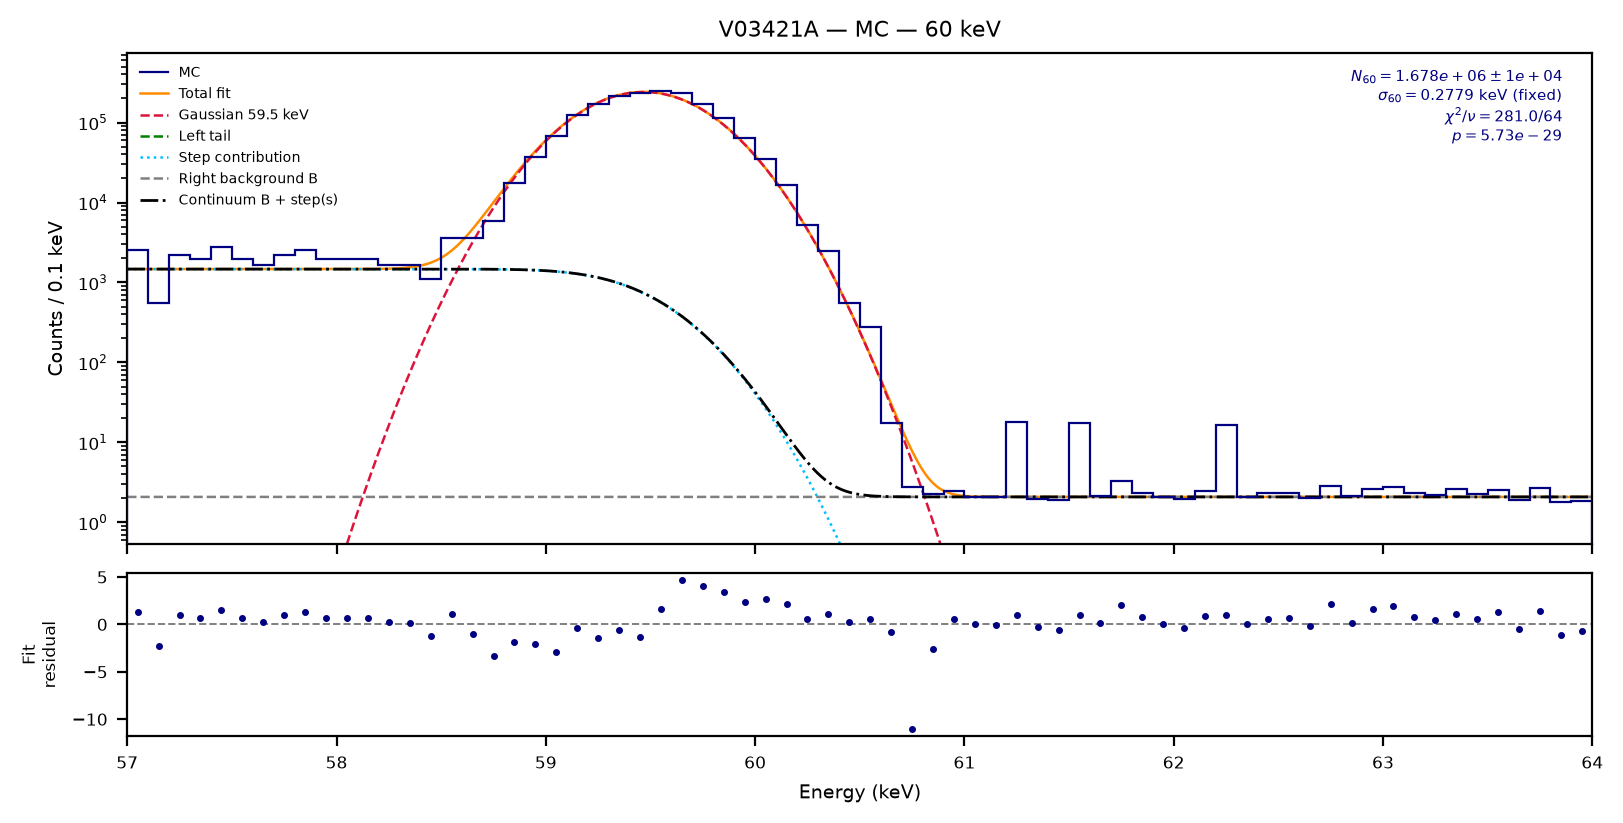


MC — regione 100 keV
sigma99      = 0.300562 keV — fissata
sigma103     = 0.302763 keV — fissata
N99          = 16085.3 ± 503
mu99         = 99.0014 ± 0.0105
N103         = 12361.5 ± 432
mu103        = 102.858 ± 0.00601
B100         = 39.993 ± 1.34
S100         = 0.148555 ± 0.128

Livelli asintotici del continuo:
right           = 39.993 ± 1.34 counts/keV
step_height     = 5.94117 ± 5.16 counts/keV
left            = 45.9341 ± 4.98 counts/keV

Chi² / ndof = 459.14 / 114
Chi² ridotto = 4.028
p-value = 6.01e-43


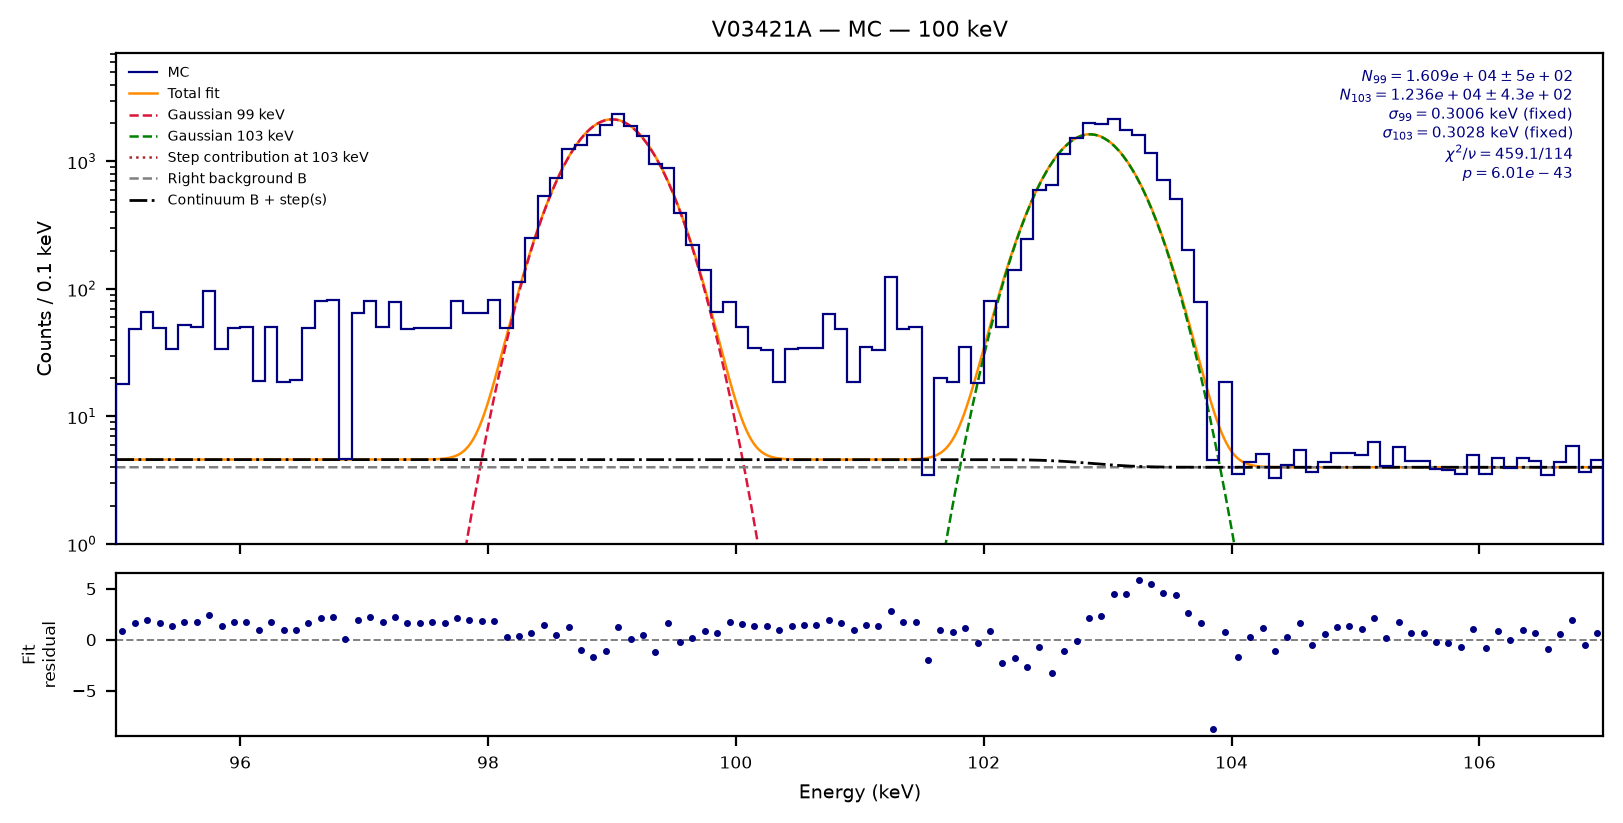

In [357]:
result60_MC = fit_am_peak(
    counts_MC_teo,
    bins,
    region="60",
    sample="MC",
    variance=variance_MC_teo,
    detector=detector,
    plot=True,
)

result100_MC = fit_am_peak(
    counts_MC_teo,
    bins,
    region="100",
    sample="MC",
    variance=variance_MC_teo,
    detector=detector,
    plot=True,
)


MC — regione 60 keV
sigma60      = 0.277906 keV — fissata
N60          = 859276 ± 1.56e+04
mu60         = 59.3991 ± 0.00259
N60_tail     = 0.0883695 ± 418
tau60        = 9.78202 ± 6.17
B60          = 18.4578 ± 0.566
S60          = 482.458 ± 76.6

Livelli asintotici del continuo:
right           = 18.4578 ± 0.566 counts/keV
step_height     = 8905.14 ± 1.39e+03 counts/keV
left            = 8923.6 ± 1.39e+03 counts/keV

Chi² / ndof = 735.67 / 64
Chi² ridotto = 11.495
p-value = 8.137e-115


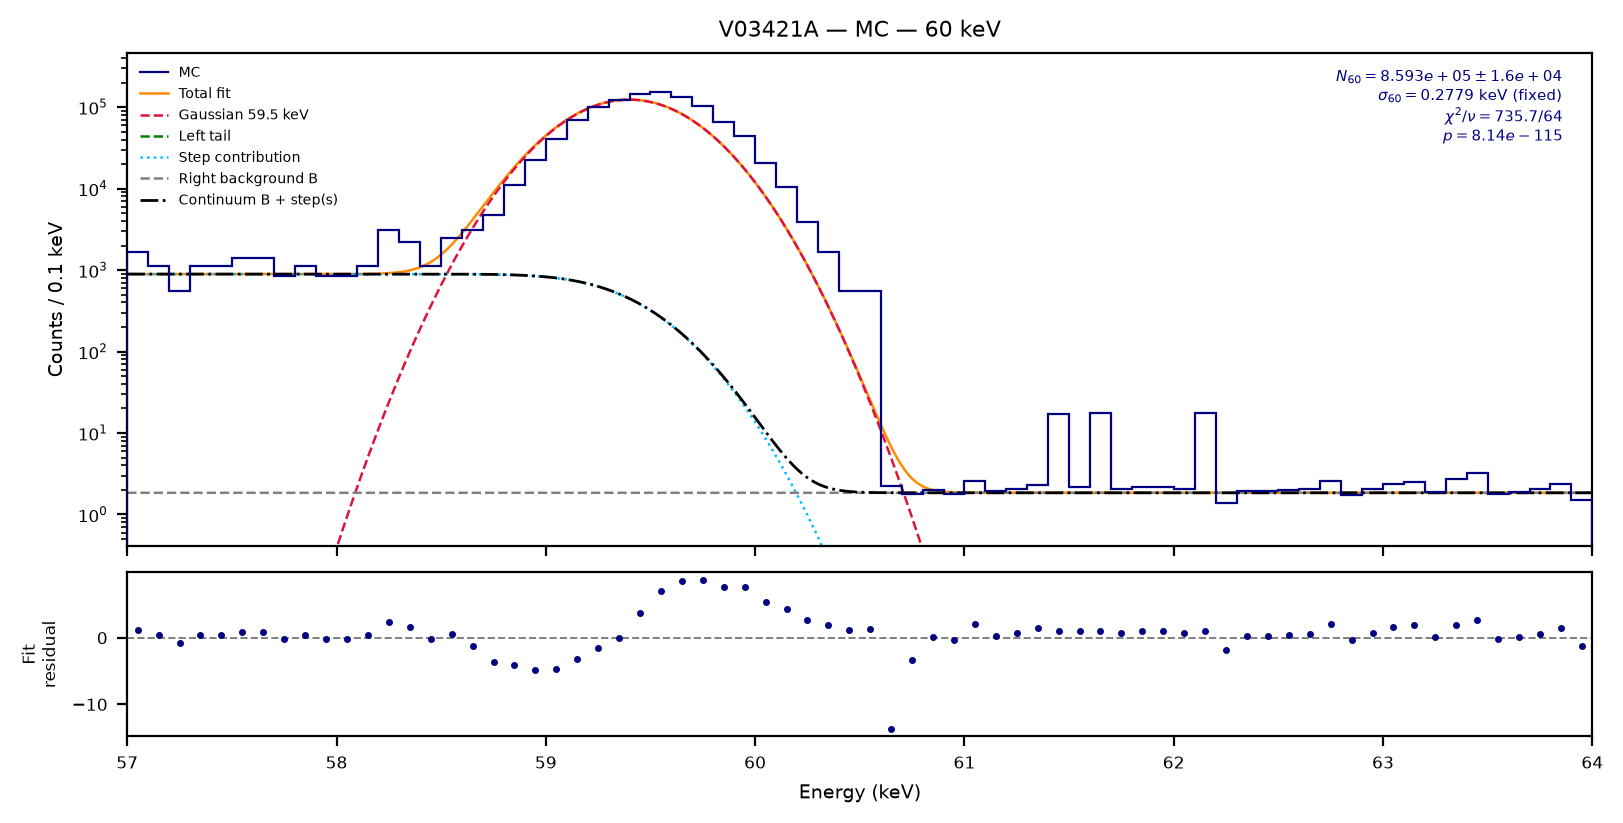


MC — regione 100 keV
sigma99      = 0.300562 keV — fissata
sigma103     = 0.302763 keV — fissata
N99          = 14065.3 ± 470
mu99         = 99.0029 ± 0.0103
N103         = 12462.1 ± 433
mu103        = 102.926 ± 0.00687
B100         = 35.1586 ± 1.12
S100         = 2.11452e-06 ± 0.0413

Livelli asintotici del continuo:
right           = 35.1586 ± 1.12 counts/keV
step_height     = 7.43435e-05 ± 0.021 counts/keV
left            = 35.1587 ± 1.12 counts/keV

Chi² / ndof = 281.47 / 114
Chi² ridotto = 2.469
p-value = 3.596e-16


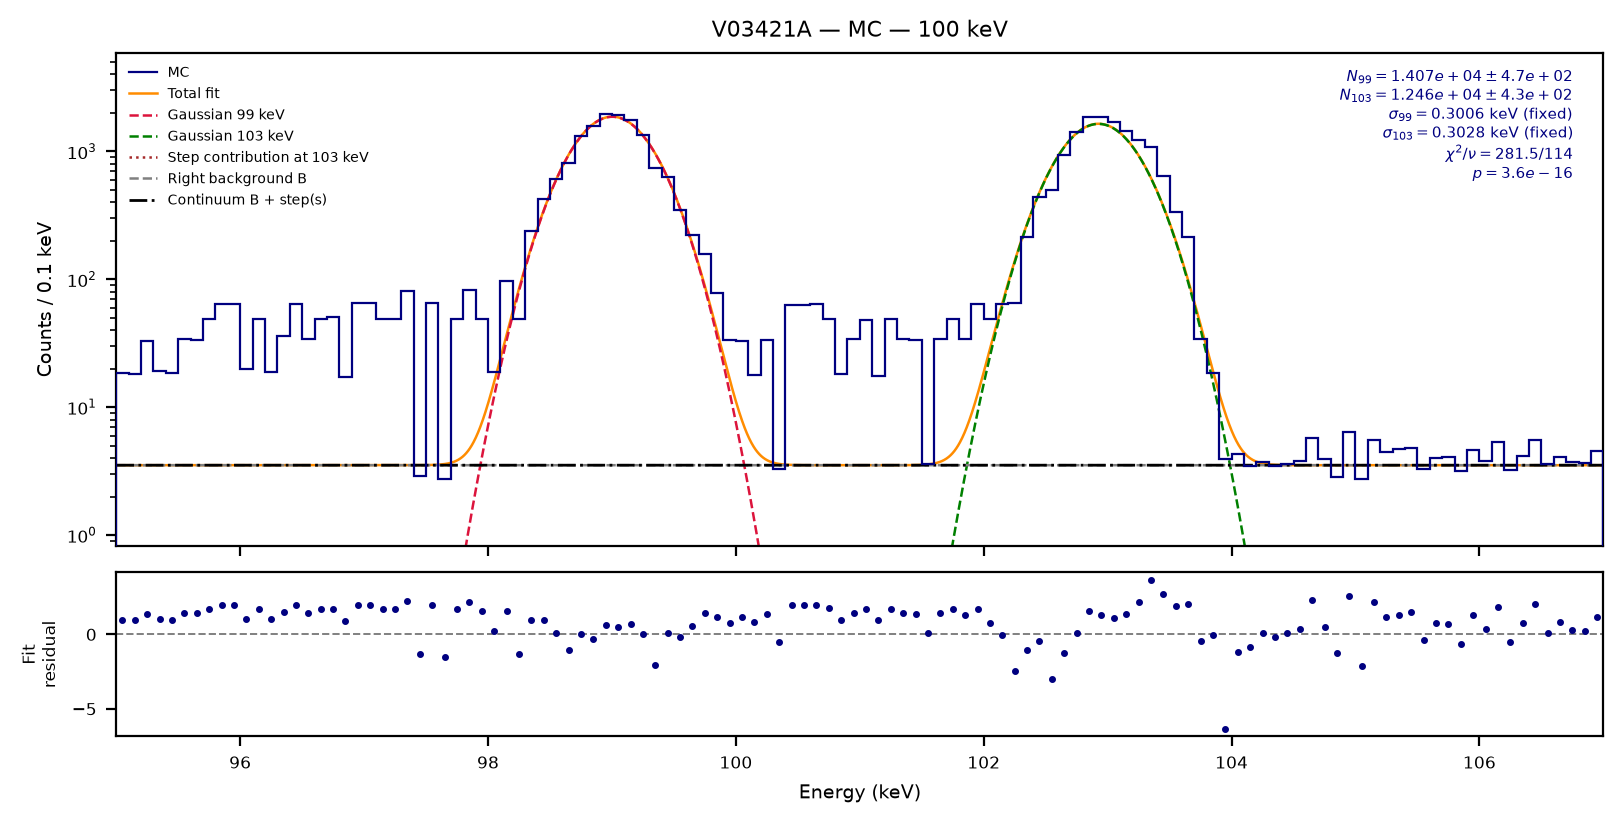

In [358]:
# stessi plot ma con la CCE

result60_MC = fit_am_peak(
    counts_MC_cce,
    bins,
    region="60",
    sample="MC",
    variance=variance_MC_cce,
    detector=detector,
    plot=True,
)

result100_MC = fit_am_peak(
    counts_MC_cce,
    bins,
    region="100",
    sample="MC",
    variance=variance_MC_cce,
    detector=detector,
    plot=True,
)
